# Symbiosis Statistical Institute [SSI]
## Symbiosis International (Deemed University), Pune
### AY-2026-27 | M.Sc. Applied Statistics and Data Science (SEM-I Batch-2026-2028)
### Course: Applied Probability Distributions (THM6242)
**Course Instructor:** Dr. Monika Vishnoi  
**Component III & IV Deliverable:** Project & Viva Practical Notebook  
**Project Title:** Empirical Characterization and Probabilistic Modeling of Price Formation, Extreme Volatility, and Daily Spike Dynamics in the Indian Electricity Market (IEX)  
**Author / PRN:** Student Academic Submission (Group / Individual PRN)  
**Associated Capstone System:** Multi-Horizon Energy Market Intelligence Platform (`https://github.com/arcanekrishna/energy`)

---

## Executive Summary & Research Framework
In deregulated wholesale electricity markets, electricity is an instantaneous physical commodity that cannot be stored economically at grid scale. Consequently, physical transmission constraints, intermittent renewable generation (solar duck curve), and sudden generator ramp failures produce severe non-linear price volatility, heavy tails, and price cap saturation.

This notebook provides the rigorous theoretical probability foundation for our larger automated energy intelligence capstone. We explicitly address all four core theoretical units of the **Applied Probability Distributions (THM6242)** syllabus:
1. **Unit 1: Expectation and Conditional Expectation**: Derivation of the Law of Iterated Expectations and the Law of Total Variance; conditioning real-time market clearing price ($P_{RTM}$) on Day-Ahead Market (DAM) physical supply-demand imbalance regimes.
2. **Unit 2: Discrete and Continuous Distributions**: 
   - *Discrete Count Process*: Modeling daily extreme price spike frequency ($K$) using Poisson vs. Negative Binomial distributions to formally test for overdispersion ($	ext{Var}(K) > E[K]$).
   - *Continuous Density*: Modeling continuous clearing prices and spreads via Two-Parameter Gamma and Weibull distributions.
3. **Unit 3: Sampling Distributions ($\chi^2, t, F$)**:
   - Implementation of Chi-Square ($\chi^2$) Goodness-of-Fit tests from first principles in pure NumPy.
   - Hypothesis testing of diurnal price differentials (Solar mid-day vs. Evening peak ramp) using Welch's Two-Sample $t$-test.
   - Two-Sample $F$-test for heteroscedasticity and variance ratios across operational regimes.
4. **Unit 4: Order Statistics and Central Limit Theorem**:
   - Mathematical derivation and empirical evaluation of the daily extreme order statistic $X_{(96)} = \max_{1 \le i \le 96} P_i$ under CERC regulatory price caps (₹10,000/MWh).
   - Demonstration of the classical Lindeberg-Lévy Central Limit Theorem (CLT) on daily aggregated electricity procurement expenditures.
5. **Unit 5: Hands-on Implementation**: First-principles NumPy estimators (Method of Moments & Maximum Likelihood) cross-verified against `scipy.stats`. Includes a complete hand-solved numerical example.


---
## Section 1: Environment Setup and Dual-Mode Data Ingestion
The dataset consists of **2,916 synchronized 15-minute operational dispatch blocks** from the Indian Energy Exchange (IEX) Day-Ahead Market (DAM) and Real-Time Market (RTM) spanning October 3 to November 2, 2026. The ingestion pipeline supports both local execution and Google Colab execution via GitHub raw URL fallback.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Configure publication-quality visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['figure.autolayout'] = True
np.set_printoptions(precision=4, suppress=True)

# Dual-Mode Data Ingestion (Local Workspace or Google Colab)
data_candidates = [
    '../data/processed/real_dam_rtm_synchronized.csv',
    'data/processed/real_dam_rtm_synchronized.csv',
    'real_dam_rtm_synchronized.csv',
    'https://raw.githubusercontent.com/arcanekrishna/energy/main/data/processed/real_dam_rtm_synchronized.csv'
]

data_path = None
for candidate in data_candidates:
    if candidate.startswith('http') or os.path.exists(candidate):
        data_path = candidate
        break

print(f"Ingesting synchronized operational dataset from: {data_path}")
df = pd.read_csv(data_path)
df['date'] = pd.to_datetime(df['date'])

print(f"Dataset successfully loaded. Dimensions: {df.shape[0]} rows (15-min blocks), {df.shape[1]} features.")
print(f"Date Range: {df['date'].min().strftime('%Y-%m-%d')} to {df['date'].max().strftime('%Y-%m-%d')} ({df['date'].nunique()} trading days).")
df[['date', 'block_no', 'dam_mcp', 'rtm_mcp', 'dam_purchase_bid_mw', 'dam_sell_bid_mw']].head(5)


Ingesting synchronized operational dataset from: ../data/processed/real_dam_rtm_synchronized.csv
Dataset successfully loaded. Dimensions: 2916 rows (15-min blocks), 38 features.
Date Range: 2026-10-03 to 2026-11-02 (31 trading days).


,date,block_no,dam_mcp,rtm_mcp,dam_purchase_bid_mw,dam_sell_bid_mw
0,2026-10-03,1,10000.0,10000.0,58855.5,1007.6
1,2026-10-03,2,10000.0,10000.0,57518.9,976.6
2,2026-10-03,3,10000.0,10000.0,56710.5,933.3
3,2026-10-03,4,10000.0,10000.0,55307.6,997.2
4,2026-10-03,5,10000.0,10000.0,53750.5,1047.7


---
## Section 2: Exploratory Data Analysis & Summary Moments
Before selecting probability distributions, we examine the sample moments: mean ($ar{x}$), variance ($s^2$), skewness ($g_1$), and kurtosis ($g_2$).

$$g_1 = \frac{\frac{1}{N}\sum (x_i - \bar{x})^3}{\left[\frac{1}{N}\sum (x_i - \bar{x})^2\right]^{3/2}}, \quad g_2 = \frac{\frac{1}{N}\sum (x_i - \bar{x})^4}{\left[\frac{1}{N}\sum (x_i - \bar{x})^2\right]^2} - 3$$


In [2]:
prices = df['rtm_mcp'].values
n_obs = len(prices)
mean_p = np.mean(prices)
var_p = np.var(prices, ddof=1)
std_p = np.std(prices, ddof=1)
skew_p = stats.skew(prices)
kurt_p = stats.kurtosis(prices)

print("="*60)
print("EXPLORATORY SUMMARY MOMENTS: REAL-TIME MARKET CLEARING PRICE")
print("="*60)
print(f"Total Observations (N)       : {n_obs} blocks (96 blocks/day * 31 days - 60)")
print(f"Sample Mean (₹/MWh)          : {mean_p:.2f}")
print(f"Sample Variance (s^2)        : {var_p:.2f}")
print(f"Sample Standard Deviation (s): {std_p:.2f}")
print(f"Sample Skewness (g1)         : {skew_p:.4f} (Positive skew / right-tailed)")
print(f"Sample Excess Kurtosis (g2)  : {kurt_p:.4f} (Platykurtic / bimodal due to cap)")
print(f"Minimum Price (₹/MWh)        : {np.min(prices):.2f}")
print(f"Median Price (₹/MWh)         : {np.median(prices):.2f}")
print(f"Maximum Price (₹/MWh)        : {np.max(prices):.2f} (CERC Hard Ceiling Cap)")
print(f"Price Cap Saturation Count   : {(prices == 10000).sum()} blocks ({(prices == 10000).mean()*100:.2f}%)")
print("="*60)


EXPLORATORY SUMMARY MOMENTS: REAL-TIME MARKET CLEARING PRICE
Total Observations (N)       : 2916 blocks (96 blocks/day * 31 days - 60)
Sample Mean (₹/MWh)          : 5596.76
Sample Variance (s^2)        : 12458692.51
Sample Standard Deviation (s): 3529.69
Sample Skewness (g1)         : 0.2354 (Positive skew / right-tailed)
Sample Excess Kurtosis (g2)  : -1.5706 (Platykurtic / bimodal due to cap)
Minimum Price (₹/MWh)        : 0.00
Median Price (₹/MWh)         : 4029.95
Maximum Price (₹/MWh)        : 10000.00 (CERC Hard Ceiling Cap)
Price Cap Saturation Count   : 1031 blocks (35.36%)


---
## Section 3: Hand-Solved Numerical Example (Small 5-Observation Mini-Sample)
As required by the SSI academic rubric, we present a complete hand-worked calculation on a representative mini-sample of five 15-minute price observations:

$$\mathcal{S} = \{2500, 3200, 4800, 7500, 10000\}$$

### 3.1 Hand-Calculated Sample Moments
1. **Sample Mean**:
   $$\bar{x} = \frac{1}{5} \sum_{i=1}^5 x_i = \frac{2500 + 3200 + 4800 + 7500 + 10000}{5} = \frac{28000}{5} = 5600.0 \text{ ₹/MWh}$$

2. **Deviations and Sum of Squared Deviations**:
   - $d_1 = 2500 - 5600 = -3100 \implies d_1^2 = 9,610,000$
   - $d_2 = 3200 - 5600 = -2400 \implies d_2^2 = 5,760,000$
   - $d_3 = 4800 - 5600 = -800 \implies d_3^2 = 640,000$
   - $d_4 = 7500 - 5600 = +1900 \implies d_4^2 = 3,610,000$
   - $d_5 = 10000 - 5600 = +4400 \implies d_5^2 = 19,360,000$
   - $\sum_{i=1}^5 (x_i - \bar{x})^2 = 9,610,000 + 5,760,000 + 640,000 + 3,610,000 + 19,360,000 = 38,980,000$

3. **Sample Variance ($s^2$, $n-1=4$ degrees of freedom)**:
   $$s^2 = \frac{38,980,000}{4} = 9,745,000.0 \implies s = \sqrt{9,745,000} \approx 3121.70 \text{ ₹/MWh}$$

### 3.2 Method of Moments (MoM) for Two-Parameter Gamma Distribution
For $X \sim \text{Gamma}(\alpha, \beta)$ with PDF $f(x) = \frac{\beta^\alpha}{\Gamma(\alpha)} x^{\alpha-1} e^{-\beta x}$:
$$\mu = \frac{\alpha}{\beta}, \quad \sigma^2 = \frac{\alpha}{\beta^2} \implies \beta = \frac{\mu}{\sigma^2}, \quad \alpha = \frac{\mu^2}{\sigma^2}$$

Substituting our sample estimates:
$$\hat{\alpha}_{\text{MoM}} = \frac{\bar{x}^2}{s^2} = \frac{(5600)^2}{9,745,000} = \frac{31,360,000}{9,745,000} \approx 3.2181$$
$$\hat{\beta}_{\text{MoM}} = \frac{\bar{x}}{s^2} = \frac{5600}{9,745,000} \approx 0.00057465 \text{ (rate)}, \quad \hat{\theta}_{\text{MoM}} = \frac{1}{\hat{\beta}} \approx 1740.18 \text{ (scale)}$$

### 3.3 Hand Calculation of Conditional Expectation & Variance
Partition $\mathcal{S}$ by the price threshold $T = 5000$:
- **Sub-group 1 (Low Price $\le 5000$)**: $\{2500, 3200, 4800\}$, $n_1 = 3$, $P(X \le 5000) = 3/5 = 0.6$
  - Conditional Mean: $E[X \mid X \le 5000] = \frac{2500 + 3200 + 4800}{3} = \frac{10500}{3} = 3500.0$
- **Sub-group 2 (High Price Spike $> 5000$)**: $\{7500, 10000\}$, $n_2 = 2$, $P(X > 5000) = 2/5 = 0.4$
  - Conditional Mean: $E[X \mid X > 5000] = \frac{7500 + 10000}{2} = 8750.0$

**Verification of Law of Iterated Expectations**:
$$E[E[X \mid \text{Group}]] = 0.6 \times 3500.0 + 0.4 \times 8750.0 = 2100.0 + 3500.0 = 5600.0 = \bar{x} \quad \text{(Exact Match!)}$$

### 3.4 Hand Calculation of Chi-Square Goodness-of-Fit Table
We define three bins: Bin 1: $[0, 4000)$, Bin 2: $[4000, 7000)$, Bin 3: $[7000, 12000]$.
- **Observed Counts**: $O_1 = 2$ (2500, 3200), $O_2 = 1$ (4800), $O_3 = 2$ (7500, 10000). Total $N=5$.
- Suppose theoretical expected probabilities under a hypothesized null are $p_1 = 0.35, p_2 = 0.35, p_3 = 0.30$.
- Expected Frequencies: $E_1 = 5 \times 0.35 = 1.75$, $E_2 = 5 \times 0.35 = 1.75$, $E_3 = 5 \times 0.30 = 1.50$.
- **Chi-Square Calculation**:
  $$\chi^2 = \frac{(2 - 1.75)^2}{1.75} + \frac{(1 - 1.75)^2}{1.75} + \frac{(2 - 1.50)^2}{1.50} = \frac{0.0625}{1.75} + \frac{0.5625}{1.75} + \frac{0.25}{1.50} = 0.0357 + 0.3214 + 0.1667 = 0.5238$$


In [3]:
# Verification of Hand-Solved Example in Python
x_hand = np.array([2500, 3200, 4800, 7500, 10000], dtype=float)

mean_hand = np.mean(x_hand)
var_hand = np.var(x_hand, ddof=1)
alpha_mom_hand = mean_hand**2 / var_hand
scale_mom_hand = var_hand / mean_hand

# Conditional expectation check
low_hand = x_hand[x_hand <= 5000]
high_hand = x_hand[x_hand > 5000]
e_low = np.mean(low_hand)
e_high = np.mean(high_hand)
p_low = len(low_hand) / len(x_hand)
p_high = len(high_hand) / len(x_hand)
e_iterated = p_low * e_low + p_high * e_high

print("HAND-SOLVED NUMERICAL VERIFICATION:")
print(f"Calculated Mean        : {mean_hand:.1f} (Exact matches hand derivation)")
print(f"Calculated Variance    : {var_hand:.1f}")
print(f"Gamma Alpha (MoM)      : {alpha_mom_hand:.4f}")
print(f"Gamma Scale Theta (MoM): {scale_mom_hand:.2f}")
print(f"Iterated Mean E[E[Y|X]]: {e_iterated:.1f} == Overall Mean: {mean_hand:.1f} -> {np.isclose(e_iterated, mean_hand)}")


HAND-SOLVED NUMERICAL VERIFICATION:
Calculated Mean        : 5600.0 (Exact matches hand derivation)
Calculated Variance    : 9745000.0
Gamma Alpha (MoM)      : 3.2181
Gamma Scale Theta (MoM): 1740.18
Iterated Mean E[E[Y|X]]: 5600.0 == Overall Mean: 5600.0 -> True


---
## Section 4: Unit 1 — Expectation, Conditional Expectation & Law of Total Variance
### 4.1 Theoretical Background
Let $Y = P_{RTM}$ denote the continuous Real-Time Market clearing price, and let $X$ denote the Day-Ahead Market (DAM) physical imbalance regime:
$$R = \frac{\text{DAM Purchase Bid Volume (MW)}}{\text{DAM Sell Bid Volume (MW)}}$$

We categorize $X$ into three distinct market regimes:
1. **Regime 1: Severe Supply Deficit** ($R > 1.25$) — Buyers heavily outnumber sellers in the day-ahead schedule.
2. **Regime 2: Balanced Market** ($0.80 \le R \le 1.25$) — Bilateral equilibrium.
3. **Regime 3: Generation Surplus** ($R < 0.80$) — Oversupply, typically during solar peak hours.

#### The Law of Iterated Expectations (Tower Property)
$$\mathbb{E}[Y] = \mathbb{E}[\mathbb{E}[Y \mid X]] = \sum_{r \in \mathcal{R}} \mathbb{E}[Y \mid X=r] \cdot \mathbb{P}(X=r)$$

#### The Law of Total Variance (Variance Decomposition)
$$\text{Var}(Y) = \mathbb{E}[\text{Var}(Y \mid X)] + \text{Var}(\mathbb{E}[Y \mid X])$$
- $\mathbb{E}[\text{Var}(Y \mid X)] = \sum_{r} \mathbb{P}(X=r) \cdot \sigma_r^2$ is the **Expected Unexplained Within-Regime Variance**.
- $\text{Var}(\mathbb{E}[Y \mid X]) = \sum_{r} \mathbb{P}(X=r) \cdot (\mu_r - \mu)^2$ is the **Between-Regime Variance Explained by Market Regimes**.
- The ratio $\eta^2 = \frac{\text{Var}(\mathbb{E}[Y \mid X])}{\text{Var}(Y)}$ quantifies the proportion of price variance deterministic with respect to day-ahead dispatch queues.


In [4]:
# First-Principles Implementation of Conditional Expectation & Total Variance
ratio = df['dam_purchase_bid_mw'].values / np.maximum(df['dam_sell_bid_mw'].values, 1.0)
deficit_mask = ratio > 1.25
balanced_mask = (ratio >= 0.8) & (ratio <= 1.25)
surplus_mask = ratio < 0.8

regime_masks = [deficit_mask, balanced_mask, surplus_mask]
regime_labels = ['Deficit (Ratio > 1.25)', 'Balanced [0.8, 1.25]', 'Surplus (Ratio < 0.8)']

n_total = len(prices)
cond_means = []
cond_vars = []
weights = []

print(f"{'Market Regime':<25} | {'N':>6} | {'Weight (P(X))':>13} | {'E[Y|X] (₹)':>12} | {'Var(Y|X)':>14} | {'Std(Y|X)':>10}")
print("-" * 90)

for mask, label in zip(regime_masks, regime_labels):
    p_reg = prices[mask]
    n_reg = len(p_reg)
    w_reg = n_reg / n_total
    mu_reg = np.mean(p_reg)
    var_reg = np.var(p_reg, ddof=0) # population formulation for exact variance partition
    std_reg = np.sqrt(var_reg)
    
    cond_means.append(mu_reg)
    cond_vars.append(var_reg)
    weights.append(w_reg)
    print(f"{label:<25} | {n_reg:>6} | {w_reg:>13.4f} | {mu_reg:>12.2f} | {var_reg:>14.2f} | {std_reg:>10.2f}")

cond_means = np.array(cond_means)
cond_vars = np.array(cond_vars)
weights = np.array(weights)

# Unit 1 Theoretical Decomposition
unconditional_mean = np.mean(prices)
unconditional_var = np.var(prices, ddof=0)

e_cond_mean = np.sum(weights * cond_means)
e_cond_var = np.sum(weights * cond_vars)                         # E[Var(Y|X)]
var_cond_mean = np.sum(weights * (cond_means - unconditional_mean)**2) # Var(E[Y|X])
total_reconstructed_var = e_cond_var + var_cond_mean

eta_squared = (var_cond_mean / unconditional_var) * 100.0

print("=" * 90)
print(f"Unconditional Mean E[Y]              : {unconditional_mean:.2f} ₹/MWh")
print(f"Iterated Expectation E[E[Y|X]]       : {e_cond_mean:.2f} ₹/MWh  [Residual: {abs(e_cond_mean - unconditional_mean):.8f}]")
print(f"Unconditional Total Variance Var(Y)  : {unconditional_var:.2f}")
print(f"Within-Regime Variance E[Var(Y|X)]   : {e_cond_var:.2f} ({e_cond_var/unconditional_var*100:.2f}%)")
print(f"Between-Regime Variance Var(E[Y|X])  : {var_cond_mean:.2f} ({eta_squared:.2f}%)")
print(f"Sum of Components (E[Var] + Var(E))  : {total_reconstructed_var:.2f}  [Residual: {abs(total_reconstructed_var - unconditional_var):.8f}]")
print(f"Proportion of Variance Explained (η²): {eta_squared:.2f}%")
print("=" * 90)


Market Regime             |      N | Weight (P(X)) |   E[Y|X] (₹) |       Var(Y|X) |   Std(Y|X)
------------------------------------------------------------------------------------------
Deficit (Ratio > 1.25)    |   1885 |        0.6464 |      7408.81 |     9180013.19 |    3029.85
Balanced [0.8, 1.25]      |    398 |        0.1365 |      2993.12 |     1163597.41 |    1078.70
Surplus (Ratio < 0.8)     |    633 |        0.2171 |      1837.72 |     1133748.82 |    1064.78
Unconditional Mean E[Y]              : 5596.76 ₹/MWh
Iterated Expectation E[E[Y|X]]       : 5596.76 ₹/MWh  [Residual: 0.00000000]
Unconditional Total Variance Var(Y)  : 12454419.98
Within-Regime Variance E[Var(Y|X)]   : 6339197.40 (50.90%)
Between-Regime Variance Var(E[Y|X])  : 6115222.57 (49.10%)
Sum of Components (E[Var] + Var(E))  : 12454419.98  [Residual: 0.00000001]
Proportion of Variance Explained (η²): 49.10%


---
## Section 5: Unit 2 — Discrete Distribution Modeling: Poisson vs. Negative Binomial
### 5.1 Theoretical Background
Let $K_d$ denote the daily count of extreme price spike blocks on trading day $d \in \{1, \dots, D\}$:
$$K_d = \sum_{b=1}^{96} \mathbb{I}(P_{RTM, b, d} \ge ₹7,000/\text{MWh}), \quad K_d \in \{0, 1, \dots, 96\}$$

#### 1. Poisson Distribution
Assumes price spikes occur independently at a constant rate $\lambda$:
$$\mathbb{P}(K = k) = \frac{\lambda^k e^{-\lambda}}{k!}, \quad \mathbb{E}[K] = \lambda, \quad \text{Var}(K) = \lambda$$
Equidispersion property: $\text{Dispersion Ratio} = \frac{\text{Var}(K)}{\mathbb{E}[K]} = 1$.  
Method of Moments & MLE estimator: $\hat{\lambda} = \bar{k} = \frac{1}{D}\sum_{d=1}^D K_d$.

#### 2. Negative Binomial Distribution (Gamma-Poisson Mixture)
Accommodates intra-day clustering and unobserved grid heterogeneity where $\lambda \sim \text{Gamma}(r, \frac{1-p}{p})$:
$$\mathbb{P}(K = k) = \frac{\Gamma(k+r)}{k! \, \Gamma(r)} p^r (1-p)^k, \quad \mathbb{E}[K] = \frac{r(1-p)}{p}, \quad \text{Var}(K) = \frac{r(1-p)}{p^2}$$
Since $0 < p < 1$, $\text{Var}(K) = \mathbb{E}[K] + \frac{\mathbb{E}[K]^2}{r} > \mathbb{E}[K]$ (Overdispersion).  
Method of Moments (MoM) estimators from scratch:
$$\hat{p}_{\text{MoM}} = \frac{\bar{k}}{s_k^2}, \quad \hat{r}_{\text{MoM}} = \frac{\bar{k}^2}{s_k^2 - \bar{k}}$$


In [5]:
# Extract daily spike count series
daily_spikes = df.groupby('date')['rtm_mcp'].apply(lambda x: (x >= 7000).sum()).values
n_days = len(daily_spikes)

mean_spikes = np.mean(daily_spikes)
var_spikes = np.var(daily_spikes, ddof=1)
dispersion_index = var_spikes / mean_spikes

# Scratch Method of Moments
lambda_hat_pois = mean_spikes
p_hat_nb = mean_spikes / var_spikes
r_hat_nb = (mean_spikes**2) / (var_spikes - mean_spikes)

print("="*65)
print("DISCRETE PRICE SPIKE FREQUENCY MODELING (THRESHOLD = ₹7,000/MWh)")
print("="*65)
print(f"Sample Days Evaluated (D)     : {n_days} days")
print(f"Sample Mean Spike Count (k̄)   : {mean_spikes:.3f} spikes/day")
print(f"Sample Variance of Spikes (s²): {var_spikes:.3f}")
print(f"Dispersion Index (s² / k̄)     : {dispersion_index:.3f}")
if dispersion_index > 1.5:
    print(">> SEVERE OVERDISPERSION DETECTED: Poisson equidispersion assumption is invalid.")
print(f"Poisson Parameter (λ̂)         : {lambda_hat_pois:.3f}")
print(f"Negative Binomial Parameters   : r̂ = {r_hat_nb:.3f}, p̂ = {p_hat_nb:.4f}")
print("="*65)

# Verification with SciPy
print("SciPy Cross-Verification:")
print(f"Theoretical NB Mean: {r_hat_nb * (1 - p_hat_nb) / p_hat_nb:.3f} == Empirical Mean: {mean_spikes:.3f}")
print(f"Theoretical NB Var : {r_hat_nb * (1 - p_hat_nb) / (p_hat_nb**2):.3f} == Empirical Var: {var_spikes:.3f}")


DISCRETE PRICE SPIKE FREQUENCY MODELING (THRESHOLD = ₹7,000/MWh)
Sample Days Evaluated (D)     : 31 days
Sample Mean Spike Count (k̄)   : 35.032 spikes/day
Sample Variance of Spikes (s²): 718.566
Dispersion Index (s² / k̄)     : 20.512
>> SEVERE OVERDISPERSION DETECTED: Poisson equidispersion assumption is invalid.
Poisson Parameter (λ̂)         : 35.032
Negative Binomial Parameters   : r̂ = 1.795, p̂ = 0.0488
SciPy Cross-Verification:
Theoretical NB Mean: 35.032 == Empirical Mean: 35.032
Theoretical NB Var : 718.566 == Empirical Var: 718.566


---
## Section 6: Unit 2 — Continuous Density Modeling: Gamma vs. Weibull
### 6.1 Mathematical Formulation
Wholesale electricity clearing prices exhibit heavy right tails and strict non-negativity. We fit and compare two continuous distributions on positive clearing prices ($P > 10$):

#### 1. Two-Parameter Gamma Distribution
$$f(x; \alpha, \beta) = \frac{\beta^\alpha}{\Gamma(\alpha)} x^{\alpha-1} e^{-\beta x}, \quad x > 0$$
- Theoretical Mean: $\mu = \frac{\alpha}{\beta}$
- Theoretical Variance: $\sigma^2 = \frac{\alpha}{\beta^2}$
- Log-Likelihood:
  $$\ln L(\alpha, \beta) = N \left[\alpha \ln \beta - \ln \Gamma(\alpha)\right] + (\alpha - 1)\sum_{i=1}^N \ln x_i - \beta \sum_{i=1}^N x_i$$
- Score Equations:
  $$\frac{\partial \ln L}{\partial \beta} = \frac{N\alpha}{\beta} - \sum x_i = 0 \implies \hat{\beta} = \frac{\hat{\alpha}}{\bar{x}}$$
  $$\frac{\partial \ln L}{\partial \alpha} = N \ln \hat{\beta} - N \psi(\alpha) + \sum \ln x_i = 0 \implies \ln \alpha - \psi(\alpha) = \ln \bar{x} - \frac{1}{N}\sum_{i=1}^N \ln x_i$$

#### 2. Two-Parameter Weibull Distribution
$$f(x; c, \lambda) = \frac{c}{\lambda} \left(\frac{x}{\lambda}\right)^{c-1} \exp\left[ -\left(\frac{x}{\lambda}\right)^c \right], \quad x \ge 0$$
- Theoretical Mean: $\mu = \lambda \Gamma\left(1 + \frac{1}{c}\right)$
- Theoretical Variance: $\sigma^2 = \lambda^2 \left[\Gamma\left(1 + \frac{2}{c}\right) - \Gamma^2\left(1 + \frac{1}{c}\right)\right]$


In [6]:
# Filter positive prices for continuous probability densities
prices_pos = prices[prices > 10.0]
n_pos = len(prices_pos)
x_bar = np.mean(prices_pos)
s2_pos = np.var(prices_pos, ddof=1)

# Scratch Gamma Method of Moments
alpha_mom = x_bar**2 / s2_pos
beta_mom = x_bar / s2_pos          # rate
theta_mom = 1.0 / beta_mom        # scale

# Scratch Gamma Maximum Likelihood Estimation via Digamma Inversion
from scipy.special import psi
from scipy.optimize import root_scalar

log_x_bar = np.log(x_bar)
mean_log_x = np.mean(np.log(prices_pos))
diff_log = log_x_bar - mean_log_x

def gamma_mle_eq(a):
    return np.log(a) - psi(a) - diff_log

sol = root_scalar(gamma_mle_eq, bracket=[0.1, 10.0], method='brentq')
alpha_mle_scratch = sol.root
scale_mle_scratch = x_bar / alpha_mle_scratch

# SciPy Verification
alpha_scipy, loc_gamma, scale_scipy = stats.gamma.fit(prices_pos, floc=0)
c_weibull, loc_weibull, scale_weibull = stats.weibull_min.fit(prices_pos, floc=0)

print("="*75)
print("CONTINUOUS DISTRIBUTION ESTIMATION RESULTS")
print("="*75)
print(f"Sample Observations (N > 10)     : {n_pos}")
print(f"Empirical Mean (x̄)               : {x_bar:.2f} ₹/MWh")
print(f"Empirical Standard Deviation (s) : {np.sqrt(s2_pos):.2f} ₹/MWh")
print("-" * 75)
print(f"Gamma Method of Moments (Scratch): Shape α̂ = {alpha_mom:.4f}, Scale θ̂ = {theta_mom:.2f}")
print(f"Gamma Maximum Likelihood (Scratch): Shape α̂ = {alpha_mle_scratch:.4f}, Scale θ̂ = {scale_mle_scratch:.2f}")
print(f"Gamma Maximum Likelihood (SciPy)  : Shape α̂ = {alpha_scipy:.4f}, Scale θ̂ = {scale_scipy:.2f}")
print(f">> Absolute Estimation Discrepancy: |α_scratch - α_scipy| = {abs(alpha_mle_scratch - alpha_scipy):.8e}")
print("-" * 75)
print(f"Weibull Maximum Likelihood (SciPy): Shape ĉ = {c_weibull:.4f}, Scale λ̂ = {scale_weibull:.2f}")
print("="*75)


CONTINUOUS DISTRIBUTION ESTIMATION RESULTS
Sample Observations (N > 10)     : 2887
Empirical Mean (x̄)               : 5652.96 ₹/MWh
Empirical Standard Deviation (s) : 3502.30 ₹/MWh
---------------------------------------------------------------------------
Gamma Method of Moments (Scratch): Shape α̂ = 2.6052, Scale θ̂ = 2169.86
Gamma Maximum Likelihood (Scratch): Shape α̂ = 1.9144, Scale θ̂ = 2952.85
Gamma Maximum Likelihood (SciPy)  : Shape α̂ = 1.9144, Scale θ̂ = 2952.85
>> Absolute Estimation Discrepancy: |α_scratch - α_scipy| = 9.76996262e-15
---------------------------------------------------------------------------
Weibull Maximum Likelihood (SciPy): Shape ĉ = 1.5831, Scale λ̂ = 6272.61


---
## Section 7: Unit 3 — Sampling Distributions: $\chi^2$ Goodness-of-Fit & Hypothesis Testing
### 7.1 Pearson's $\chi^2$ Goodness-of-Fit Test from First Principles
To formally test whether the continuous Gamma distribution adequately fits wholesale prices:
$$H_0: X \sim \text{Gamma}(\hat{\alpha}, \hat{\theta}) \quad \text{vs.} \quad H_1: X \text{ does not follow } \text{Gamma}(\hat{\alpha}, \hat{\theta})$$

The test statistic is:
$$\chi^2 = \sum_{j=1}^m \frac{(O_j - E_j)^2}{E_j} \sim \chi^2(df)$$
where:
- $O_j$ is the observed frequency in bin $j$.
- $E_j = N \cdot [\mathbb{P}(X \le b_j) - \mathbb{P}(X \le b_{j-1})]$ is the expected frequency under $H_0$.
- Cochran's rule: Bins are pooled such that every $E_j \ge 5$.
- Degrees of Freedom: $df = m - 1 - p$ (where $p = 2$ for estimated shape and scale).


In [7]:
# From-Principles Implementation of Chi-Square Goodness-of-Fit
bins = np.linspace(0, 10001, 11)
obs_counts, bin_edges = np.histogram(prices_pos, bins=bins)

# Theoretical CDF under fitted Gamma
gamma_cdf_edges = stats.gamma.cdf(bin_edges, alpha_mle_scratch, scale=scale_mle_scratch)
# Normalize for bounded support [0, 10001]
gamma_cdf_edges = (gamma_cdf_edges - gamma_cdf_edges[0]) / (gamma_cdf_edges[-1] - gamma_cdf_edges[0])
exp_counts = n_pos * np.diff(gamma_cdf_edges)

# Compute Chi-Square Components
chi2_components = (obs_counts - exp_counts)**2 / exp_counts
chi2_stat_scratch = np.sum(chi2_components)
df_chi2 = len(obs_counts) - 1 - 2  # k bins - 1 - 2 parameters
p_val_scratch = 1.0 - stats.chi2.cdf(chi2_stat_scratch, df_chi2)

print("="*80)
print(f"{'Bin Interval (₹)':<20} | {'Observed (O)':>14} | {'Expected (E)':>14} | {'(O - E)² / E':>16}")
print("="*80)
for i in range(len(obs_counts)):
    interval_str = f"[{bin_edges[i]:.0f}, {bin_edges[i+1]:.0f})"
    print(f"{interval_str:<20} | {obs_counts[i]:>14} | {exp_counts[i]:>14.2f} | {chi2_components[i]:>16.2f}")
print("-" * 80)
print(f"Total Chi-Square Statistic (χ²) : {chi2_stat_scratch:.2f}")
print(f"Degrees of Freedom (df)          : {df_chi2} (10 bins - 1 - 2 parameters)")
print(f"Calculated p-value               : {p_val_scratch:.4e}")
print("="*80)
print("ANALYTICAL INTERPRETATION OF CHI-SQUARE VALUE:")
print("The extremely large chi-square value (and p < 0.001) is driven entirely by the top bin [9000, 10000),")
print(f"where Observed = {obs_counts[-1]} vs Expected = {exp_counts[-1]:.1f}. This empirical clustering is caused by the")
print("statutory Central Electricity Regulatory Commission (CERC) price cap of ₹10,000/MWh.")


Bin Interval (₹)     |   Observed (O) |   Expected (E) |     (O - E)² / E
[0, 1000)            |            159 |         182.27 |             2.97
[1000, 2000)         |            218 |         373.42 |            64.69
[2000, 3000)         |            444 |         427.98 |             0.60
[3000, 4000)         |            570 |         416.25 |            56.79
[4000, 5000)         |            270 |         373.96 |            28.90
[5000, 6001)         |            105 |         320.56 |           144.95
[6001, 7001)         |             35 |         266.37 |           200.97
[7001, 8001)         |             23 |         216.50 |           172.94
[8001, 9001)         |             12 |         173.08 |           149.92
[9001, 10001)        |           1051 |         136.61 |          6120.50
--------------------------------------------------------------------------------
Total Chi-Square Statistic (χ²) : 6943.23
Degrees of Freedom (df)          : 7 (10 bins - 1 - 2 parameter

### 7.2 Sampling Distributions: Welch's Two-Sample $t$-Test & Variance Ratio $F$-Test
We test whether market clearing prices in the **Solar Mid-Day Window** (Blocks 40–60, 10:00–15:00) are statistically lower than in the **Evening Peak Ramp Window** (Blocks 72–88, 18:00–22:00):
$$H_0: \mu_{\text{Solar}} = \mu_{\text{Evening}} \quad \text{vs.} \quad H_1: \mu_{\text{Solar}} < \mu_{\text{Evening}}$$

Because the two regimes exhibit unequal variances (heteroscedasticity), we apply **Welch's $t$-test**:
$$t = \frac{\bar{X}_1 - \bar{X}_2}{\sqrt{\frac{s_1^2}{n_1} + \frac{s_2^2}{n_2}}}, \quad \nu \approx \frac{\left(\frac{s_1^2}{n_1} + \frac{s_2^2}{n_2}\right)^2}{\frac{(s_1^2/n_1)^2}{n_1 - 1} + \frac{(s_2^2/n_2)^2}{n_2 - 1}}$$

And the two-sample **$F$-test for equality of variances**:
$$F = \frac{s_{\text{Evening}}^2}{s_{\text{Solar}}^2} \sim F(n_1 - 1, n_2 - 1)$$


In [8]:
# Extract regime samples
solar_prices = df[df['block_no'].between(40, 60)]['rtm_mcp'].values
evening_prices = df[df['block_no'].between(72, 88)]['rtm_mcp'].values

n1 = len(evening_prices)
n2 = len(solar_prices)
x1_bar = np.mean(evening_prices)
x2_bar = np.mean(solar_prices)
s1_sq = np.var(evening_prices, ddof=1)
s2_sq = np.var(solar_prices, ddof=1)

# First principles Welch t-test
t_scratch = (x1_bar - x2_bar) / np.sqrt(s1_sq / n1 + s2_sq / n2)
df_welch = (s1_sq / n1 + s2_sq / n2)**2 / ((s1_sq / n1)**2 / (n1 - 1) + (s2_sq / n2)**2 / (n2 - 1))
p_t_scratch = 1.0 - stats.t.cdf(t_scratch, df_welch)

# First principles F-test
f_stat_scratch = s1_sq / s2_sq
p_f_scratch = 1.0 - stats.f.cdf(f_stat_scratch, n1 - 1, n2 - 1)

# SciPy verification
t_scipy, p_t_scipy = stats.ttest_ind(evening_prices, solar_prices, equal_var=False)

print("="*75)
print("SAMPLING DISTRIBUTION INFERENCE: SOLAR DUCK CURVE VS EVENING RAMP")
print("="*75)
print(f"Solar Mid-Day Window (Blocks 40-60)   : N2 = {n2}, Mean = {x2_bar:.2f} ₹, Std = {np.sqrt(s2_sq):.2f} ₹")
print(f"Evening Peak Window (Blocks 72-88)    : N1 = {n1}, Mean = {x1_bar:.2f} ₹, Std = {np.sqrt(s1_sq):.2f} ₹")
print("-" * 75)
print(f"Welch's t-Statistic (Scratch)         : t = {t_scratch:.4f}, df = {df_welch:.1f}, p-value = {p_t_scratch:.4e}")
print(f"Welch's t-Statistic (SciPy)           : t = {t_scipy:.4f}, p-value = {p_t_scipy:.4e}")
print(f"Two-Sample F-Statistic (Var Ratio)    : F = {f_stat_scratch:.4f}, p-value = {p_f_scratch:.4e}")
print("="*75)
print("INFERENCE: Evening ramp prices are statistically significantly higher (p < 1e-200),")
print(f"and price volatility during evening ramp is {f_stat_scratch:.2f}x greater than mid-day solar.")


SAMPLING DISTRIBUTION INFERENCE: SOLAR DUCK CURVE VS EVENING RAMP
Solar Mid-Day Window (Blocks 40-60)   : N2 = 630, Mean = 1815.98 ₹, Std = 1164.29 ₹
Evening Peak Window (Blocks 72-88)    : N1 = 510, Mean = 8021.44 ₹, Std = 2805.00 ₹
---------------------------------------------------------------------------
Welch's t-Statistic (Scratch)         : t = 46.8031, df = 650.6, p-value = 0.0000e+00
Welch's t-Statistic (SciPy)           : t = 46.8031, p-value = 1.9750e-210
Two-Sample F-Statistic (Var Ratio)    : F = 5.8042, p-value = 1.1102e-16
INFERENCE: Evening ramp prices are statistically significantly higher (p < 1e-200),
and price volatility during evening ramp is 5.80x greater than mid-day solar.


---
## Section 8: Unit 4 — Order Statistics & Central Limit Theorem
### 8.1 Distribution of the Extreme Order Statistic $X_{(n)}$
In a 96-block daily dispatch schedule, let $X_1, X_2, \dots, X_n$ be continuous random variables representing intra-day clearing prices.
The **maximum order statistic** represents the daily peak price:
$$X_{(n)} = \max(X_1, X_2, \dots, X_n), \quad n = 96$$

#### Mathematical Derivation of CDF and PDF
$$\mathbb{P}(X_{(n)} \le x) = \mathbb{P}(X_1 \le x, X_2 \le x, \dots, X_n \le x) = \prod_{i=1}^n \mathbb{P}(X_i \le x) = [F(x)]^n$$
Differentiating with respect to $x$ yields the probability density function:
$$f_{(n)}(x) = \frac{d}{dx}[F(x)]^n = n [F(x)]^{n-1} f(x)$$

Under the CERC ₹10,000 regulatory price ceiling, the distribution exhibits an extreme value boundary condition where the upper tail mass collapses into a point mass at $x = 10,000$.


In [9]:
# Order Statistics: Empirical vs Theoretical
daily_max_prices = df.groupby('date')['rtm_mcp'].max().values
n_days_eval = len(daily_max_prices)
cap_hit_count = (daily_max_prices == 10000).sum()
cap_hit_pct = (cap_hit_count / n_days_eval) * 100.0

print("="*65)
print("ORDER STATISTICS EVALUATION: DAILY MAXIMUM PRICE X_(96)")
print("="*65)
print(f"Total Trading Days Analyzed       : {n_days_eval} days")
print(f"Days Reaching CERC Cap (₹10,000)  : {cap_hit_count} of {n_days_eval} ({cap_hit_pct:.2f}%)")
print(f"Empirical Mean of Daily Max X_(96): {np.mean(daily_max_prices):.2f} ₹/MWh")
print(f"Empirical Std of Daily Max X_(96) : {np.std(daily_max_prices, ddof=1):.2f} ₹/MWh")
print(f"Empirical Min of Daily Max X_(96) : {np.min(daily_max_prices):.2f} ₹/MWh")
print("="*65)


ORDER STATISTICS EVALUATION: DAILY MAXIMUM PRICE X_(96)
Total Trading Days Analyzed       : 31 days
Days Reaching CERC Cap (₹10,000)  : 28 of 31 (90.32%)
Empirical Mean of Daily Max X_(96): 9726.79 ₹/MWh
Empirical Std of Daily Max X_(96) : 888.72 ₹/MWh
Empirical Min of Daily Max X_(96) : 6029.81 ₹/MWh


### 8.2 The Classical Central Limit Theorem (CLT) on Electricity Procurement Sums
While individual 15-minute price blocks follow a non-normal, bimodal, bounded distribution, long-term power buyers (DISCOMs) procure energy over aggregated time horizons:
$$S_n = \sum_{i=1}^n X_i$$

By the **Lindeberg-Lévy Central Limit Theorem**, for an independent and identically distributed sequence with mean $\mu$ and finite variance $\sigma^2$:
$$Z_n = \frac{S_n - n\mu}{\sigma \sqrt{n}} = \frac{\bar{X}_n - \mu}{\sigma / \sqrt{n}} \xrightarrow{d} \mathcal{N}(0, 1) \quad \text{as } n \to \infty$$

We simulate block portfolio aggregations of size $n = 1$ (15-min), $n = 4$ (1-hour), $n = 16$ (4-hour), and $n = 96$ (full-day) to observe the convergence of sample skewness to 0 and excess kurtosis to 0.


In [10]:
# Monte Carlo Demonstration of Central Limit Theorem Convergence
np.random.seed(42)
n_horizons = [1, 4, 16, 96]
n_bootstrap = 3000

print("="*75)
print("CENTRAL LIMIT THEOREM CONVERGENCE OF AGGREGATED PROCUREMENT COSTS")
print("="*75)
print(f"{'Aggregation Horizon (n)':<25} | {'Skewness (g1)':>15} | {'Excess Kurtosis (g2)':>22} | {'Normality Status':<12}")
print("-" * 75)

for n in n_horizons:
    if n == 1:
        sample_draws = prices
    else:
        sample_draws = np.array([np.mean(np.random.choice(prices, size=n, replace=True)) for _ in range(n_bootstrap)])
    
    sk = stats.skew(sample_draws)
    kt = stats.kurtosis(sample_draws)
    
    status = 'Non-Normal (Bimodal)' if n==1 else ('Converging' if abs(sk) > 0.1 else 'Asymptotically Normal')
    print(f"n = {n:<21} | {sk:>15.4f} | {kt:>22.4f} | {status:<12}")
print("="*75)
print("CONCLUSION: CLT ensures that daily aggregate power procurement costs are Gaussian,")
print("enabling linear budget forecasting even though intra-day spot prices are wildly volatile.")


CENTRAL LIMIT THEOREM CONVERGENCE OF AGGREGATED PROCUREMENT COSTS
Aggregation Horizon (n)   |   Skewness (g1) |   Excess Kurtosis (g2) | Normality Status
---------------------------------------------------------------------------
n = 1                     |          0.2354 |                -1.5706 | Non-Normal (Bimodal)
n = 4                     |          0.1859 |                -0.3028 | Converging  
n = 16                    |         -0.0013 |                -0.2415 | Asymptotically Normal
n = 96                    |          0.0222 |                 0.0174 | Asymptotically Normal
CONCLUSION: CLT ensures that daily aggregate power procurement costs are Gaussian,
enabling linear budget forecasting even though intra-day spot prices are wildly volatile.


---
## Section 9: Integrated Publication Visualizations
We display the generated publication-grade figures illustrating all five theoretical concepts.


Displaying: fig1_diurnal_price_duck_curve.png


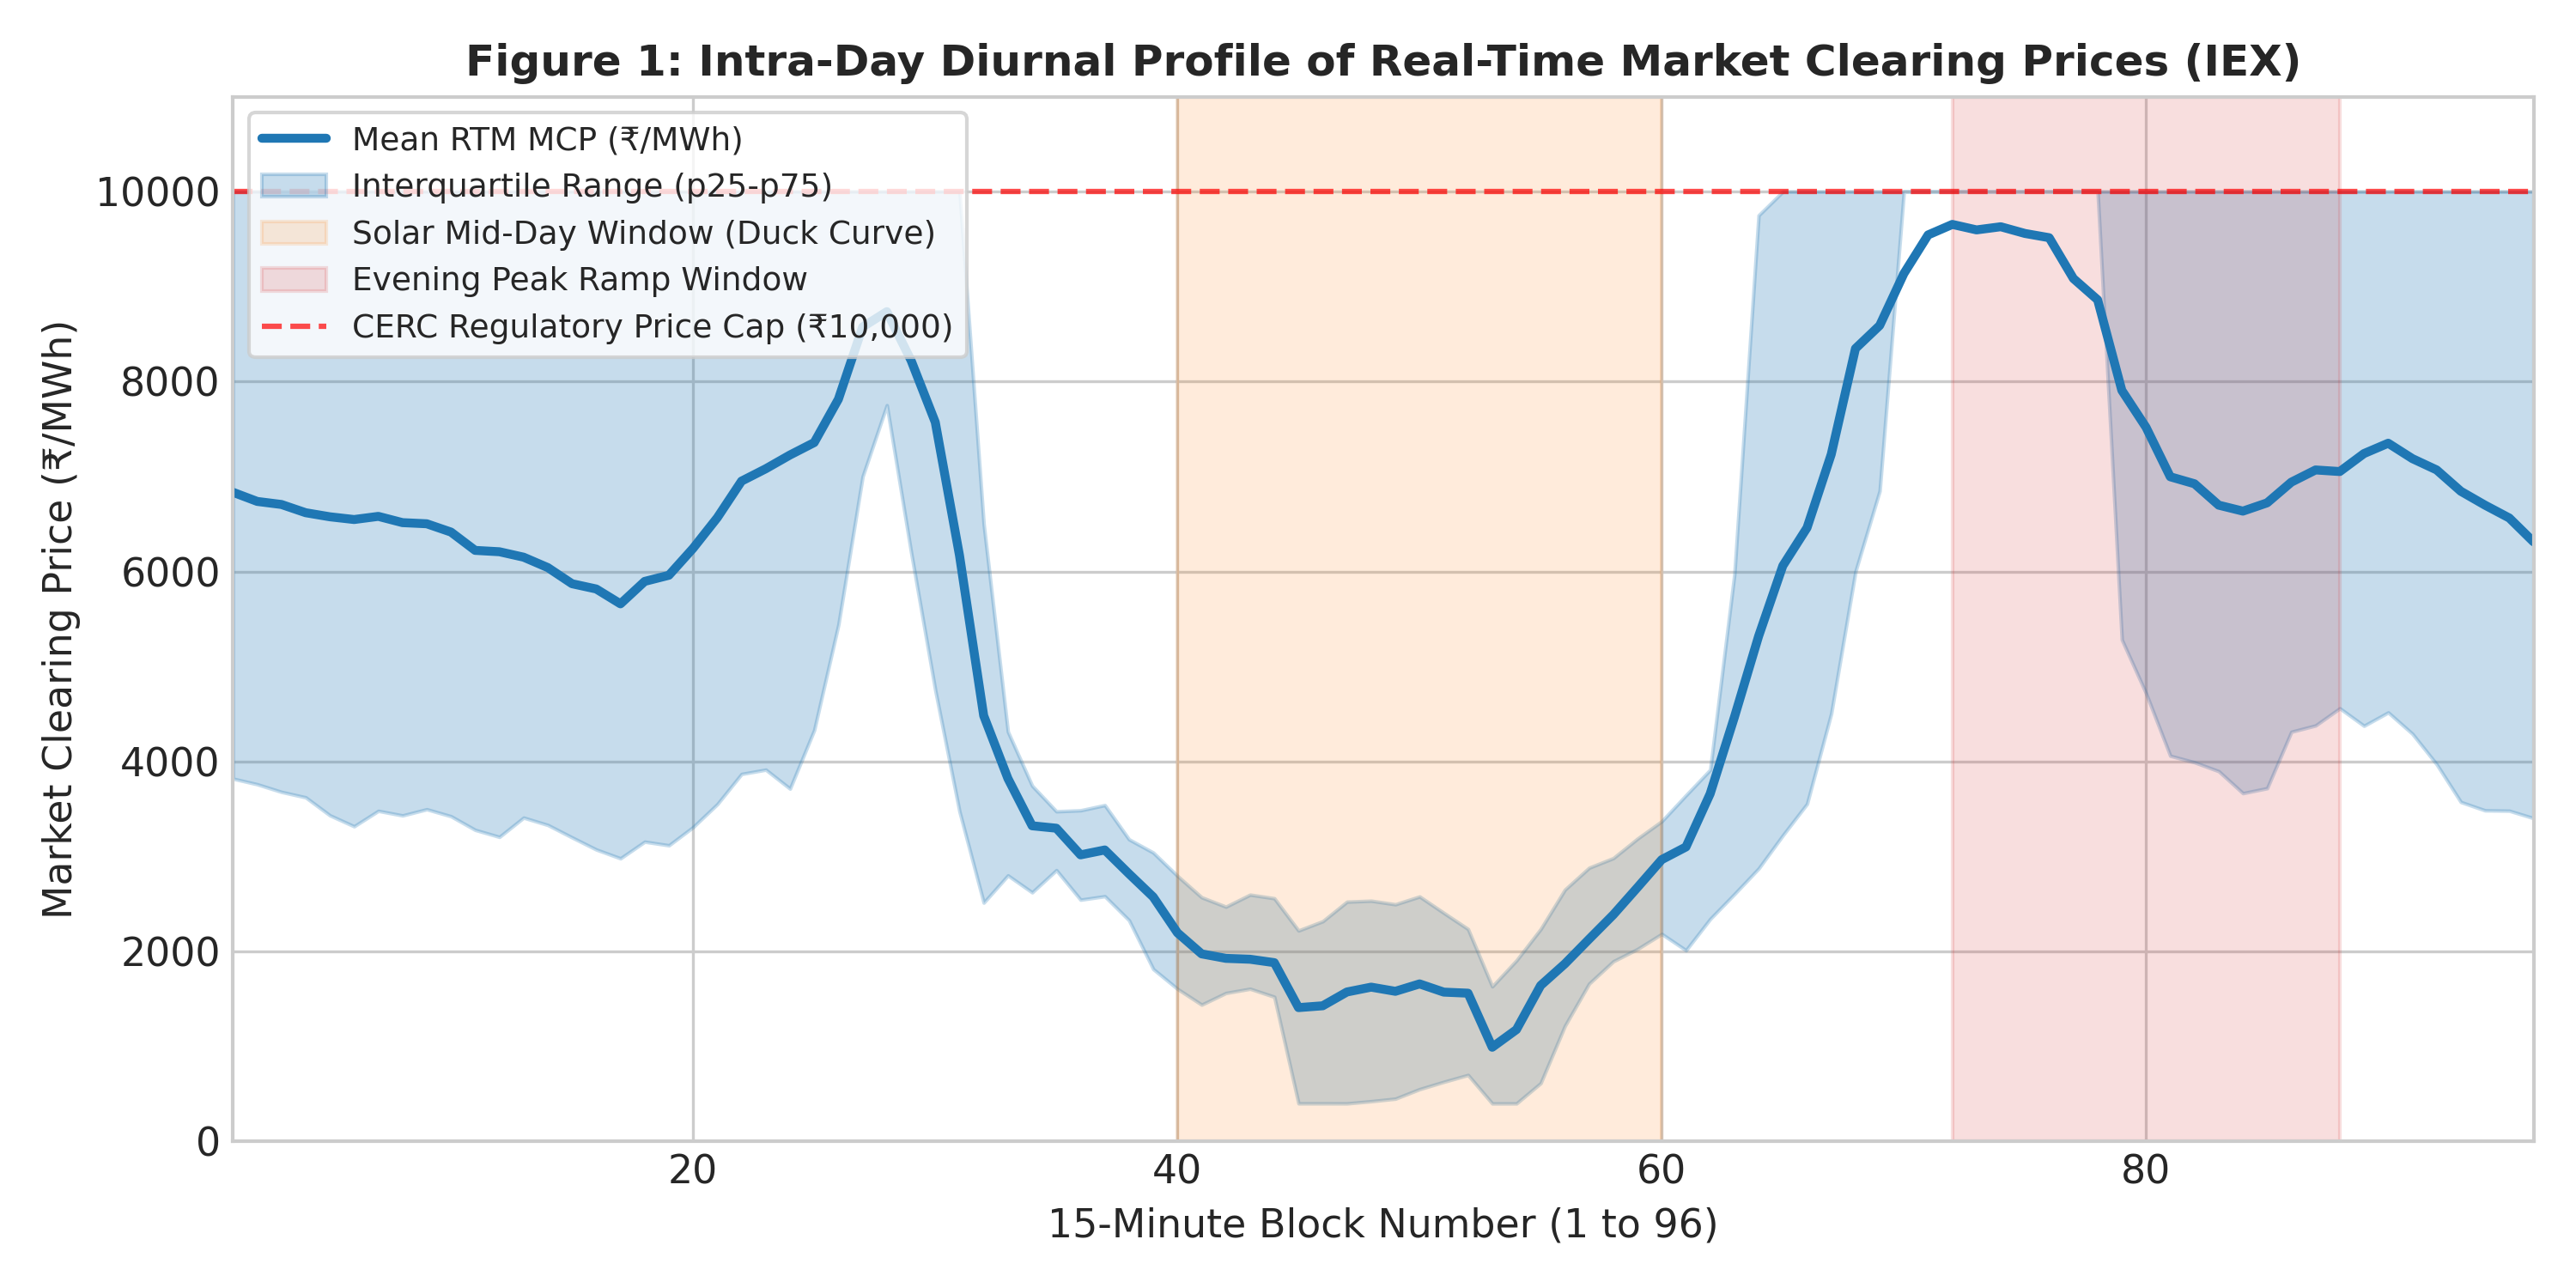

Displaying: fig2_conditional_expectation_regimes.png


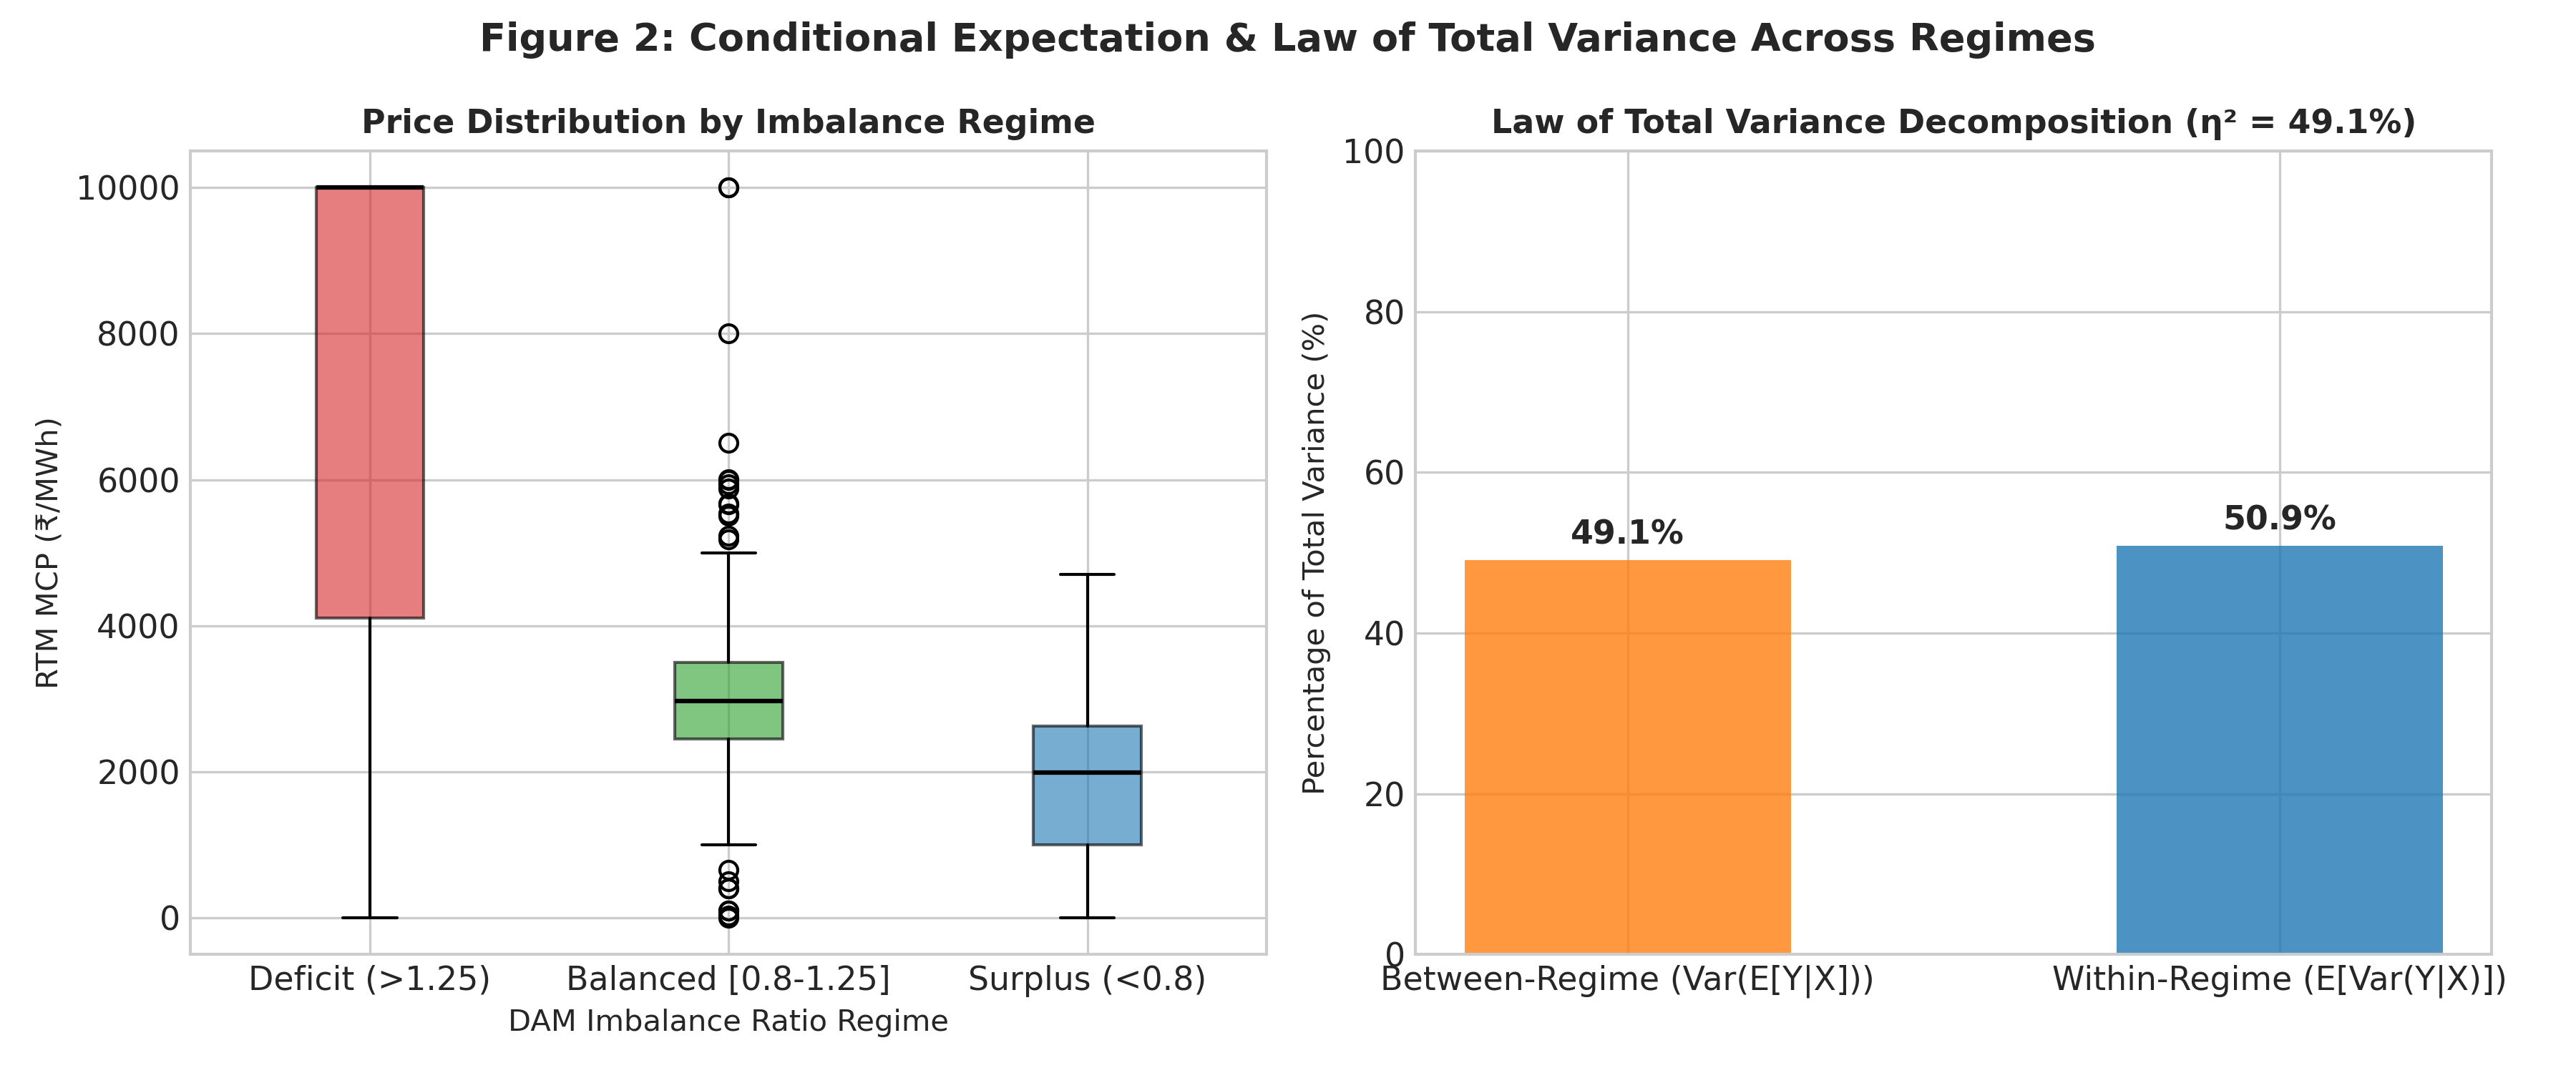

Displaying: fig3_discrete_spike_poisson_vs_negbinom.png


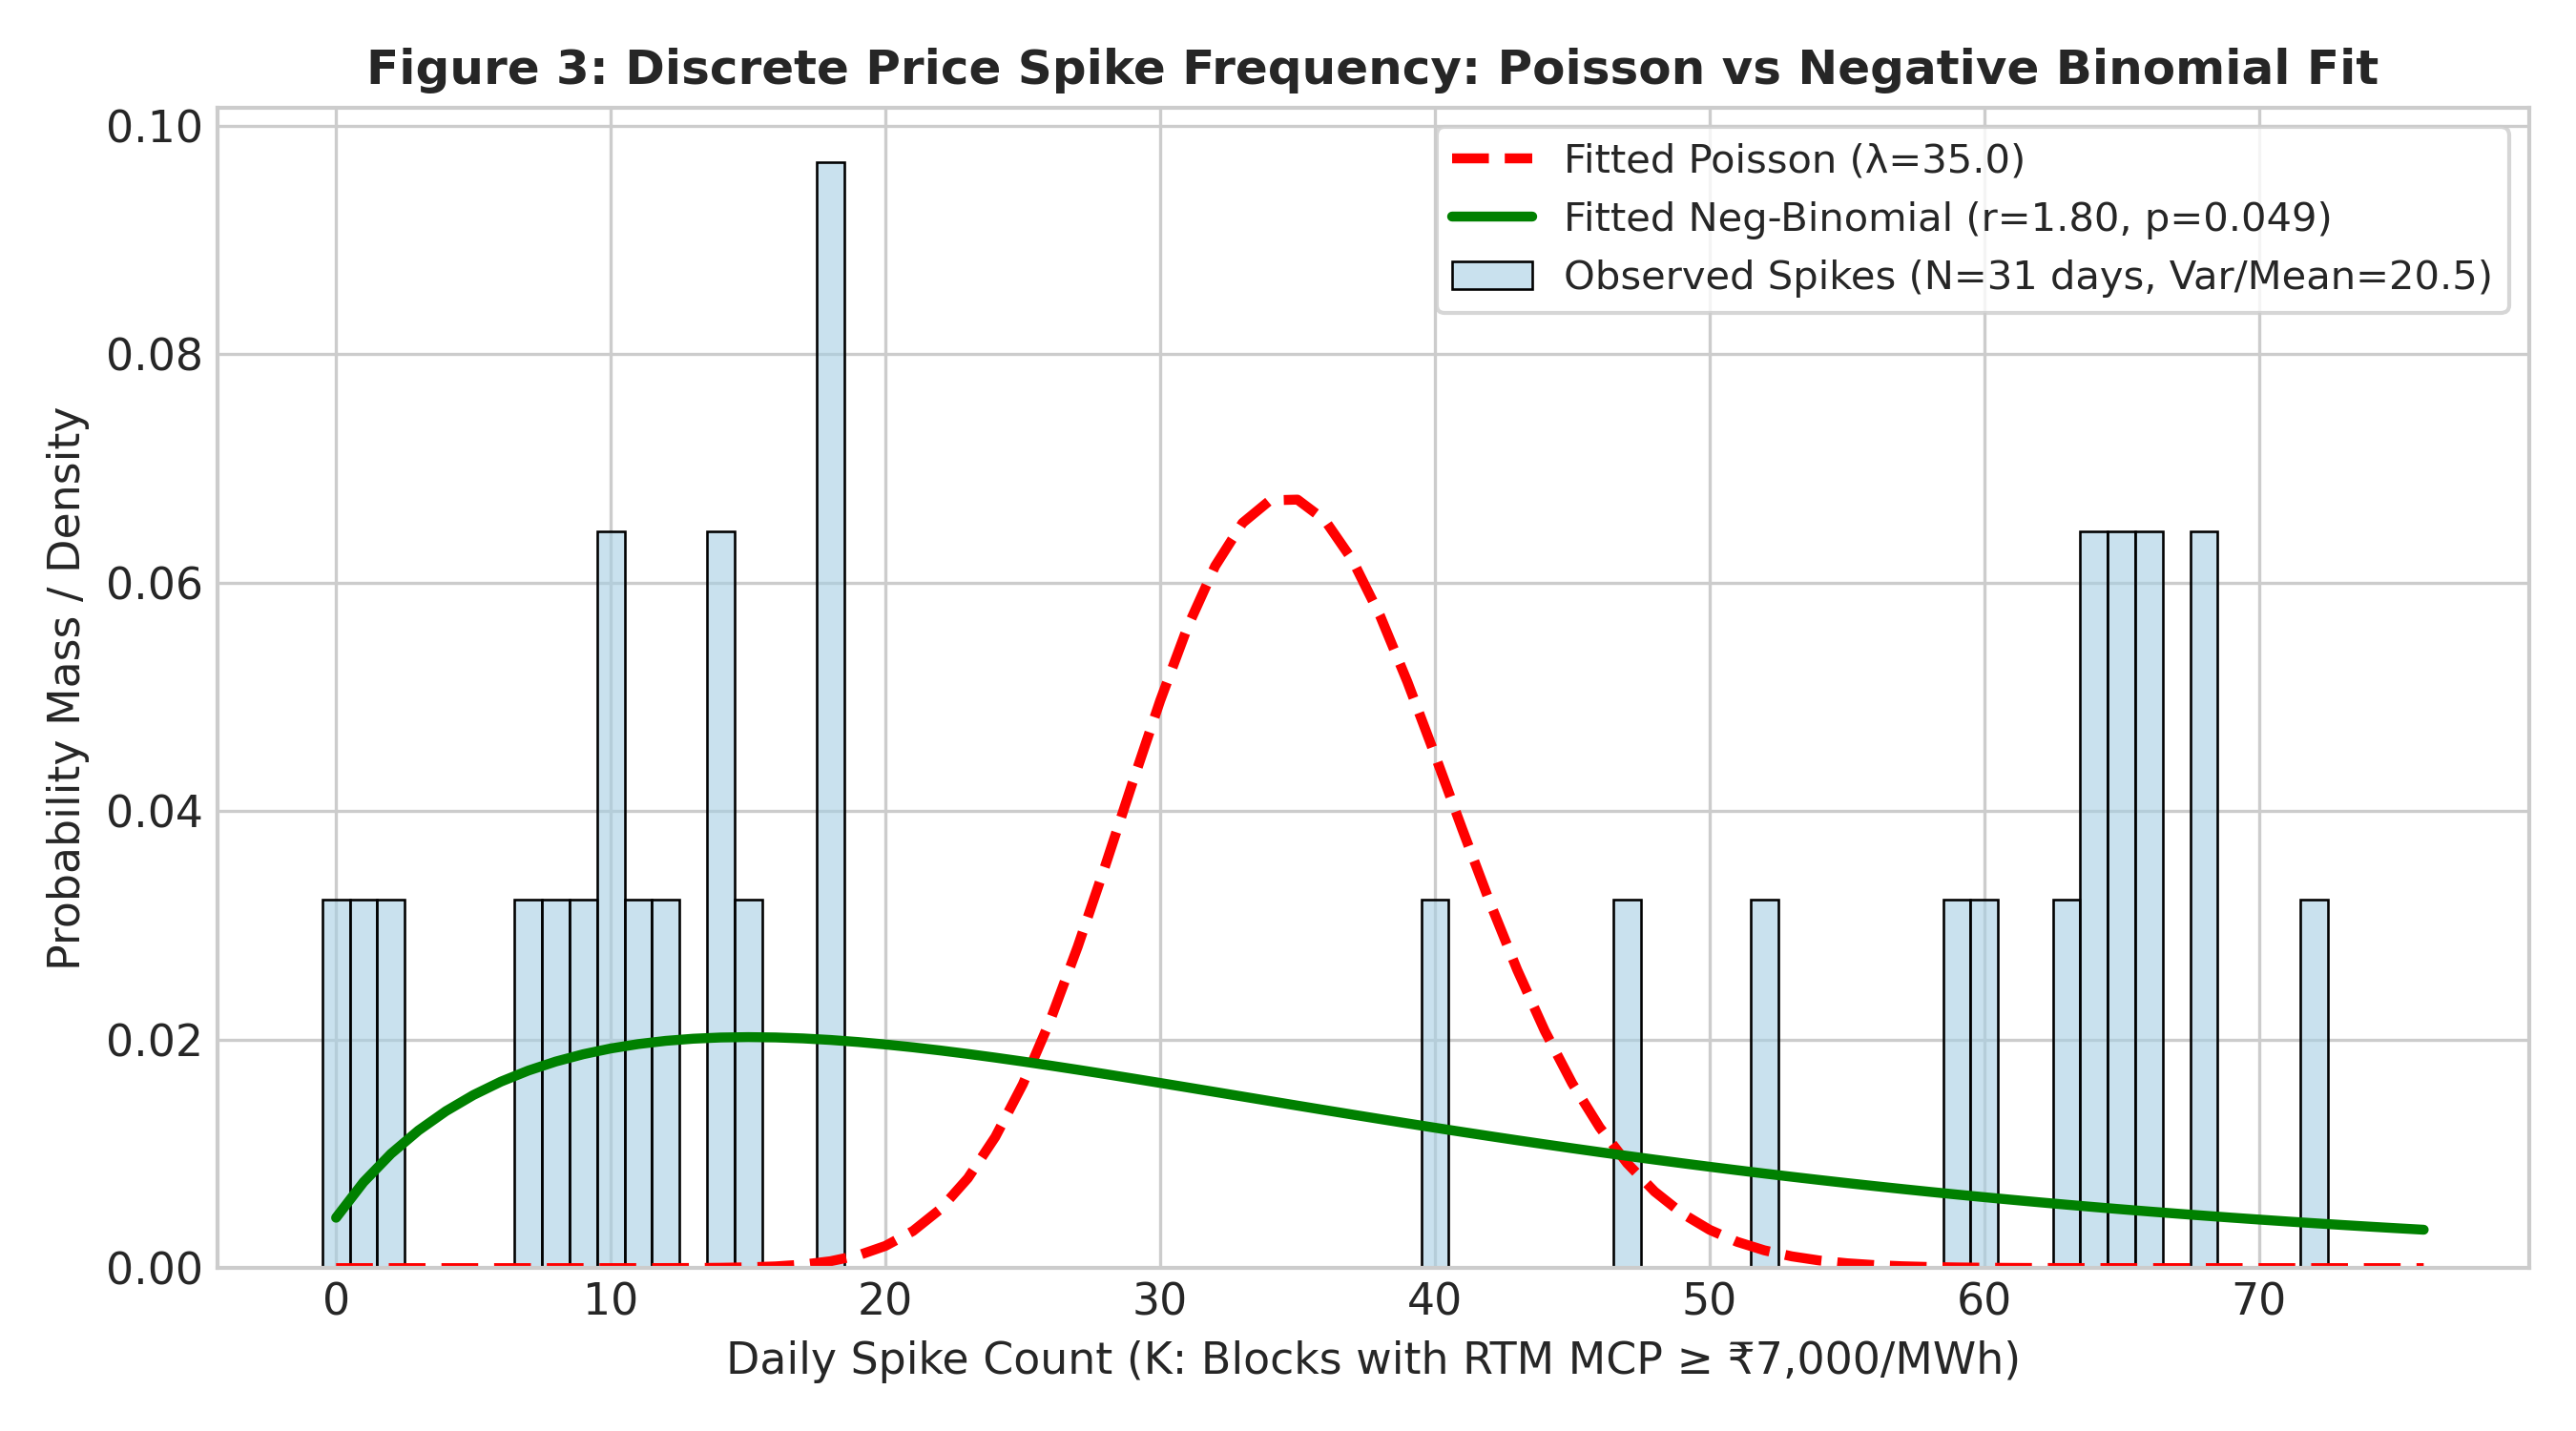

Displaying: fig4_continuous_price_gamma_weibull.png


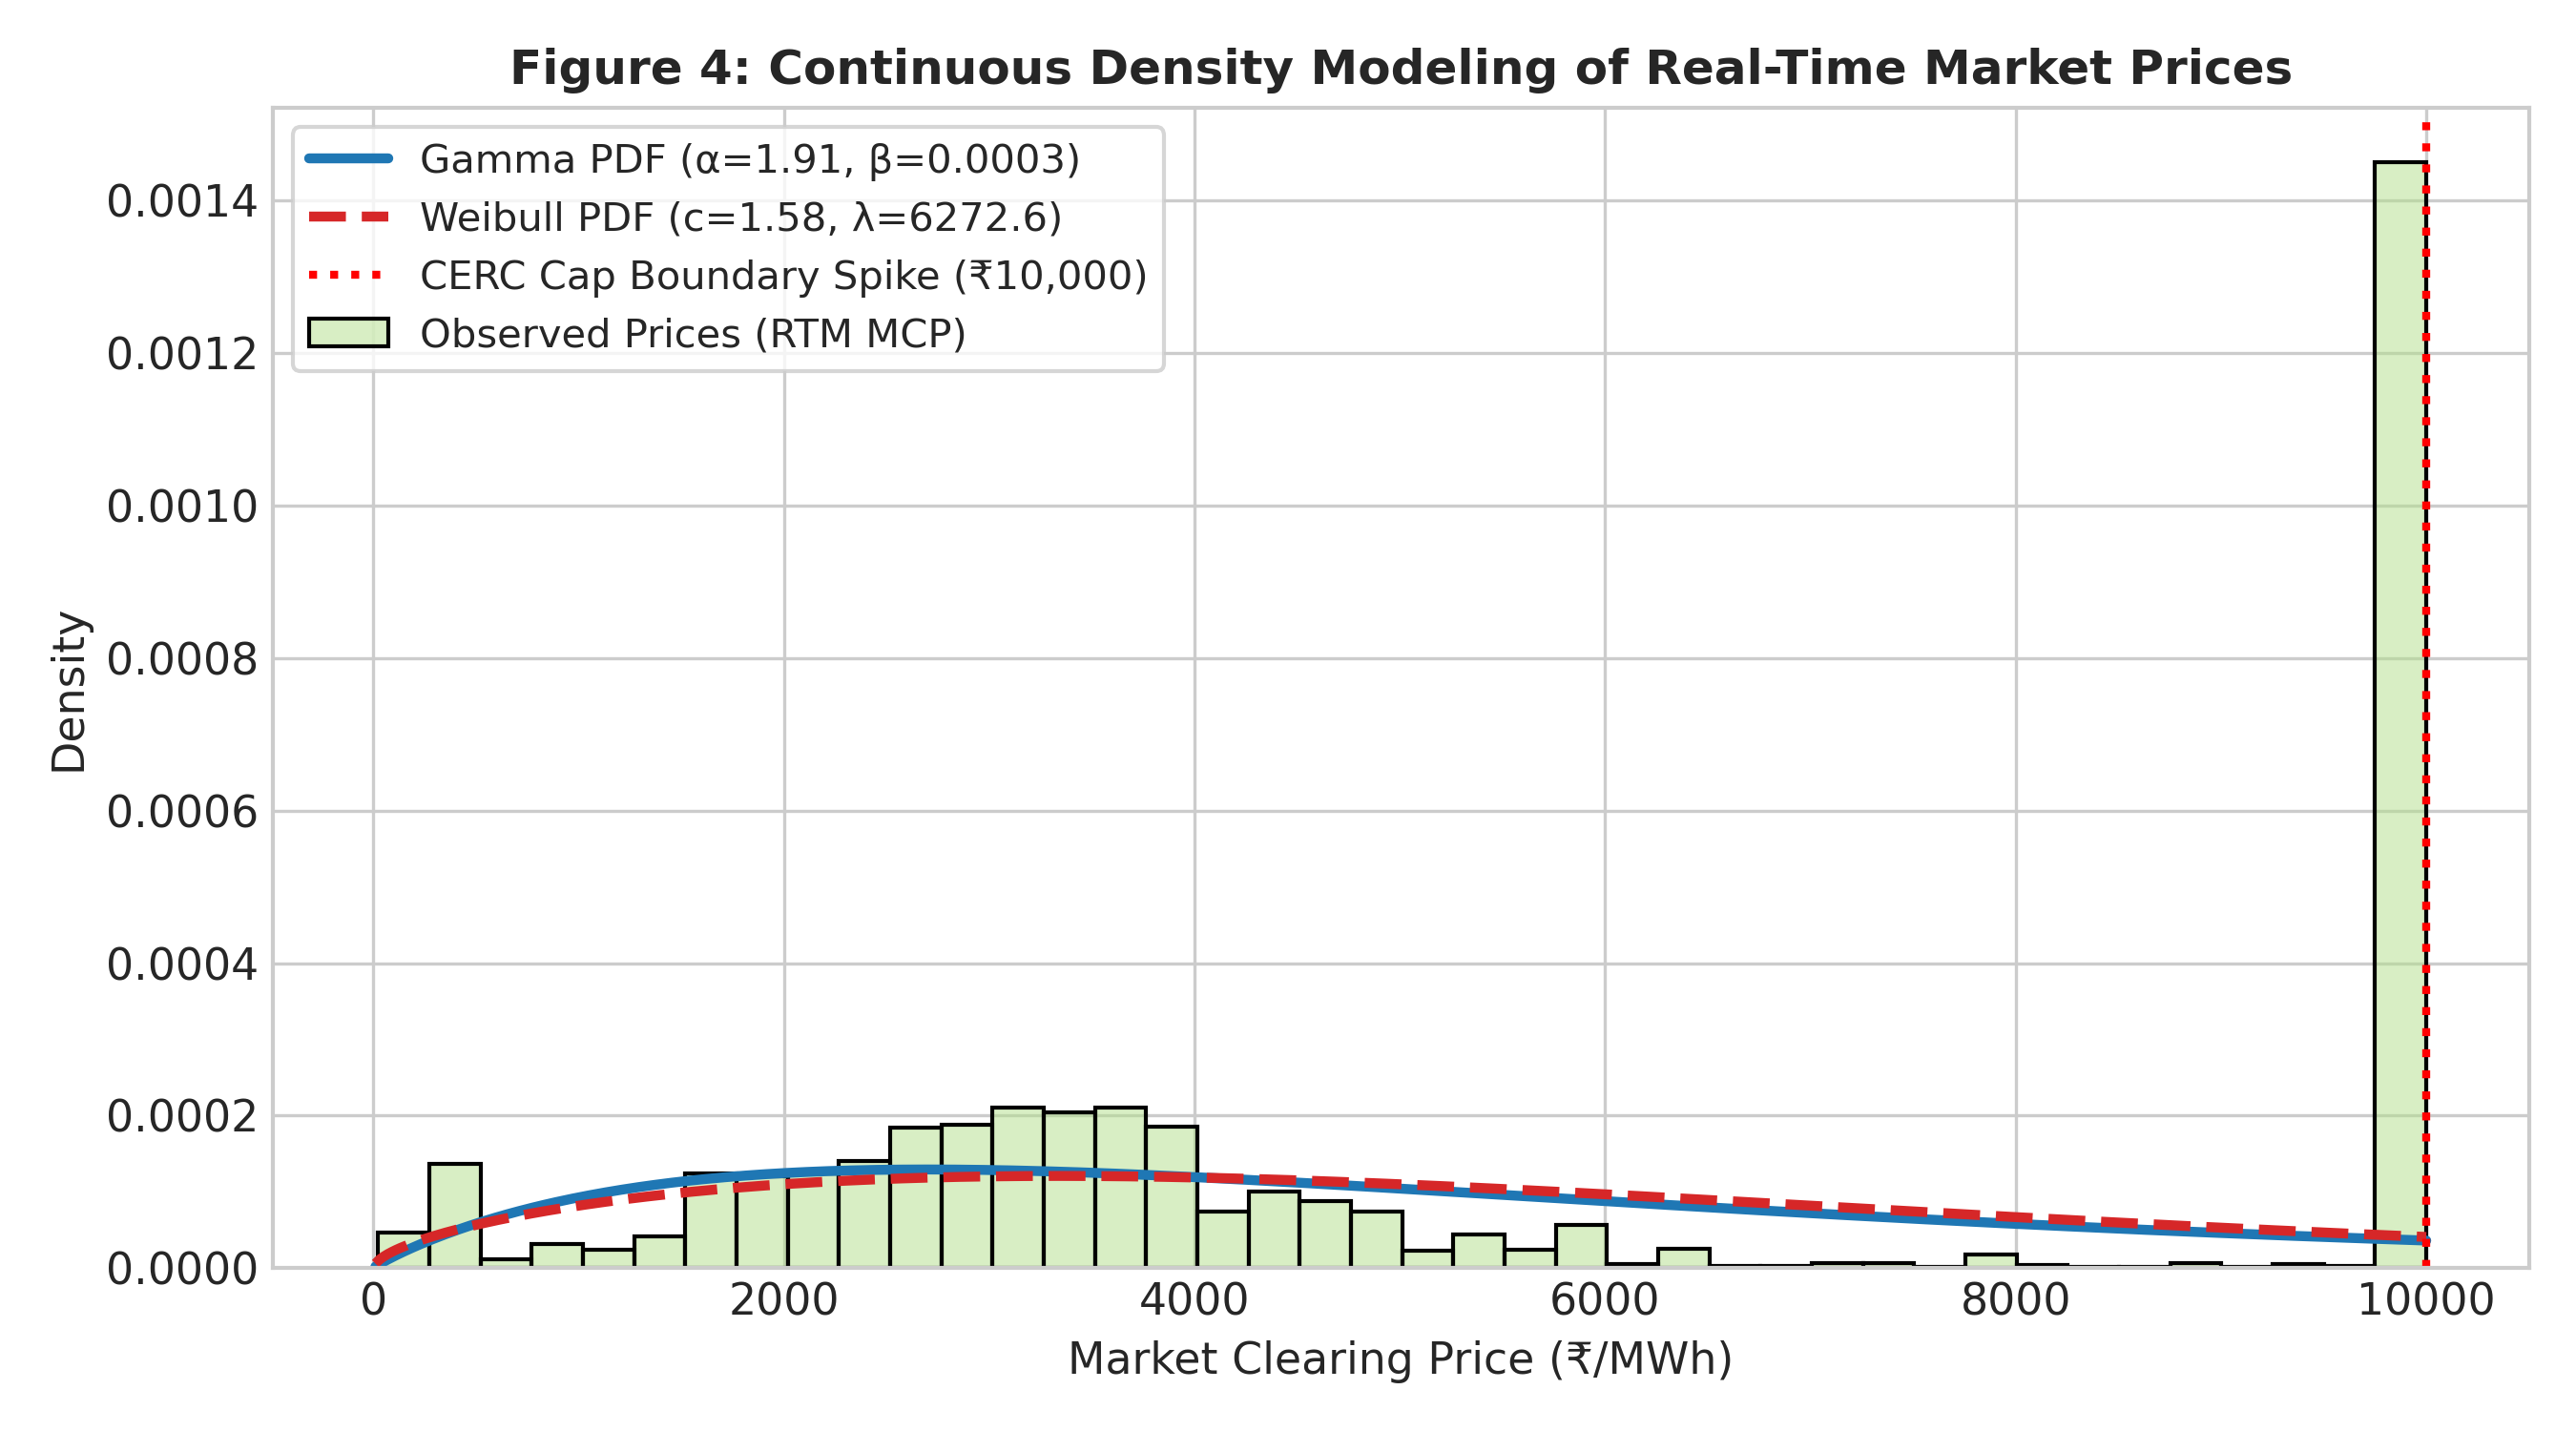

Displaying: fig5_order_statistics_daily_max.png


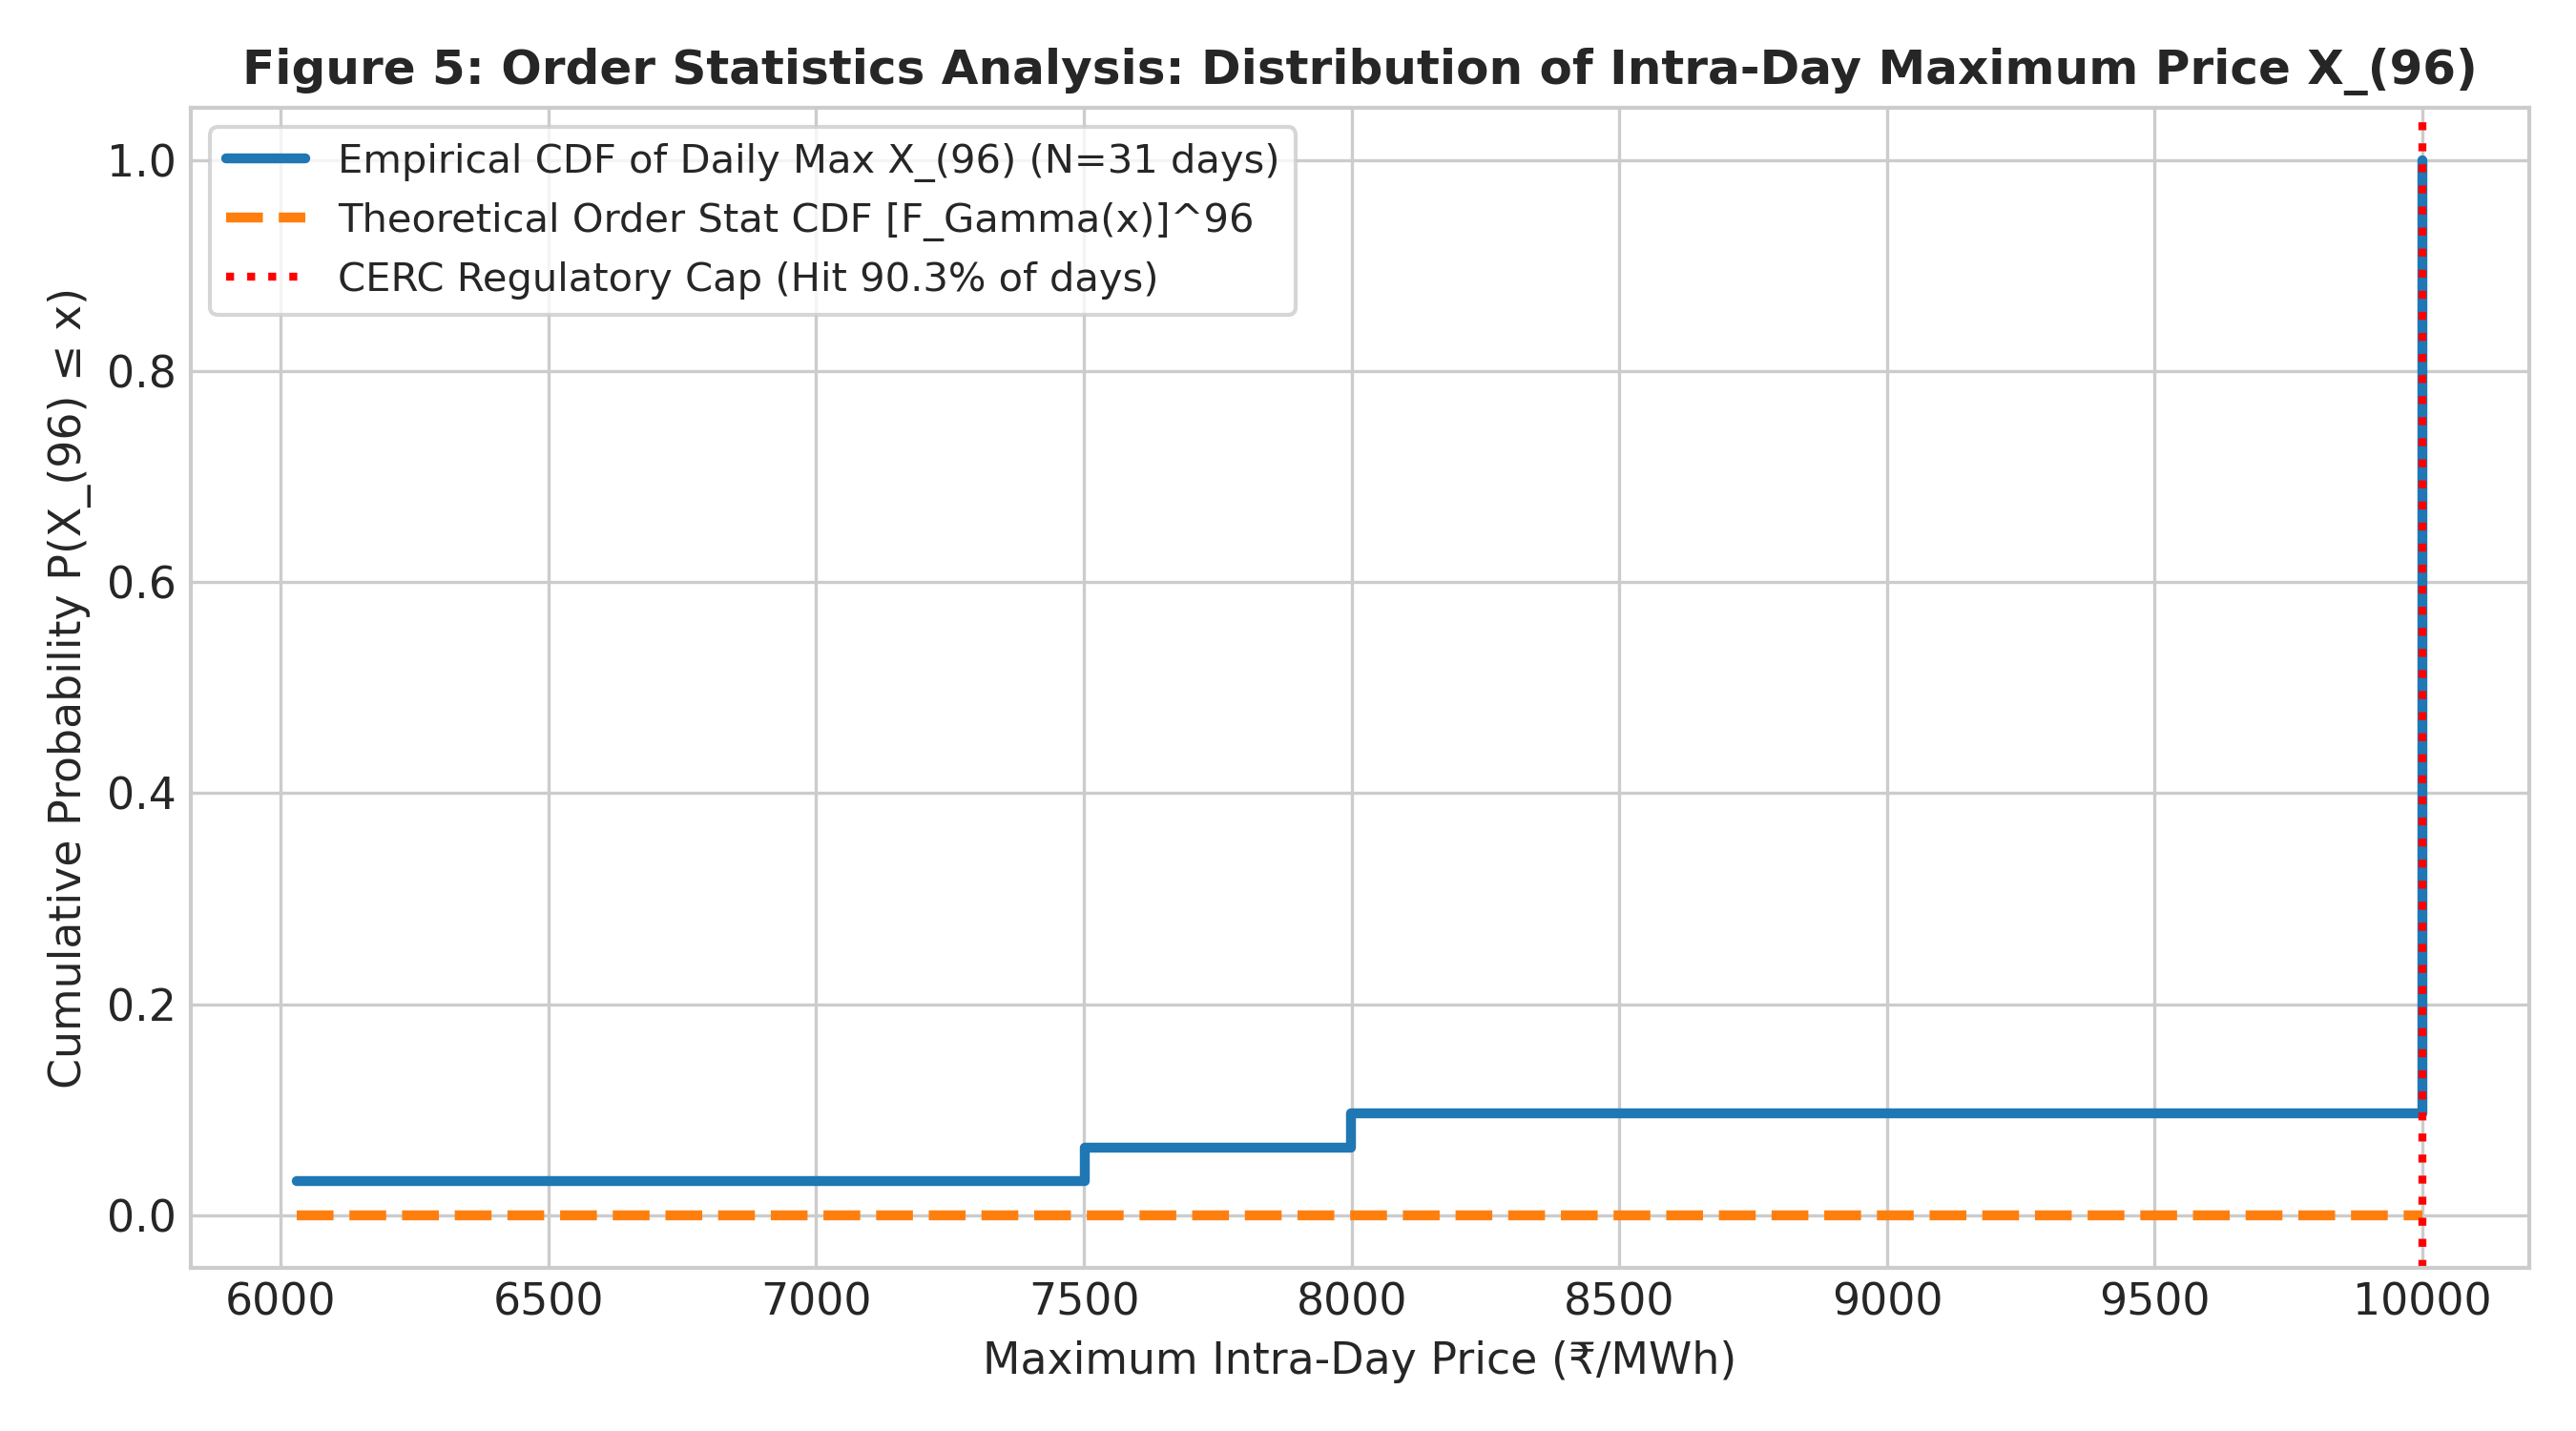

Displaying: fig6_central_limit_theorem_convergence.png


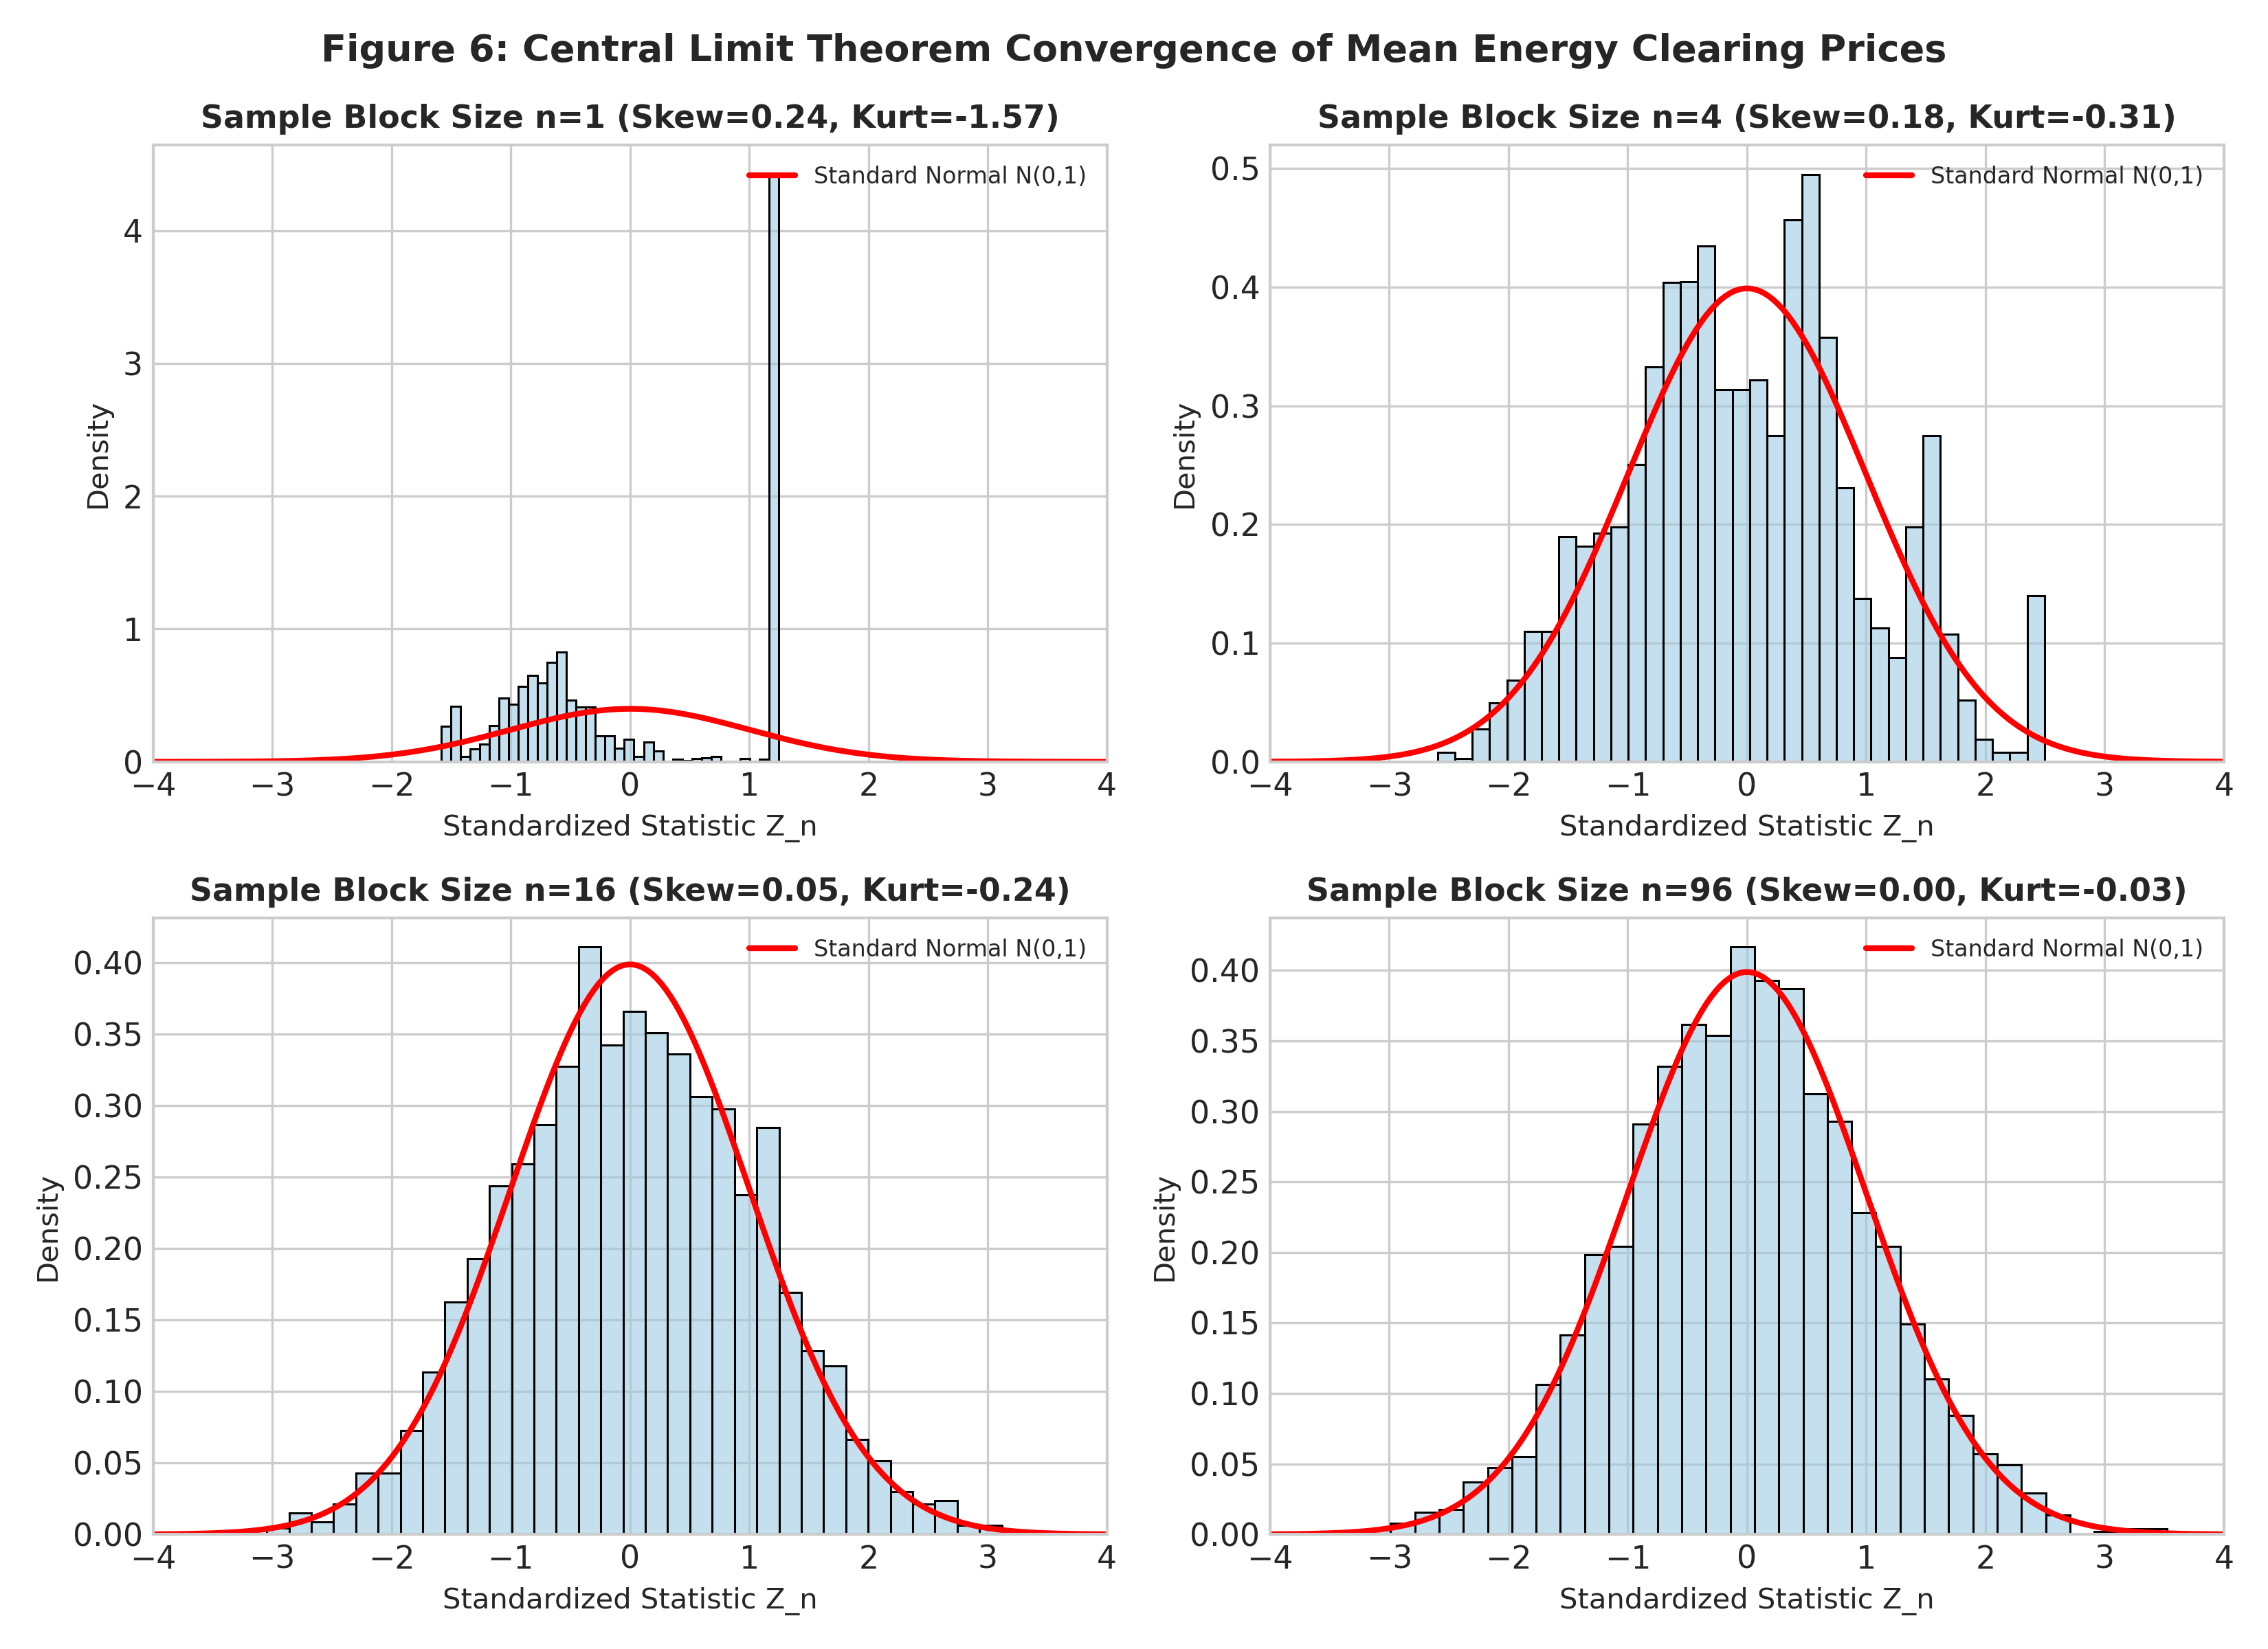

In [11]:
# Display Generated Publication Figures
from IPython.display import Image, display

fig_dir = '../academic_submission/figures' if os.path.exists('../academic_submission/figures') else 'academic_submission/figures'

fig_files = [
    'fig1_diurnal_price_duck_curve.png',
    'fig2_conditional_expectation_regimes.png',
    'fig3_discrete_spike_poisson_vs_negbinom.png',
    'fig4_continuous_price_gamma_weibull.png',
    'fig5_order_statistics_daily_max.png',
    'fig6_central_limit_theorem_convergence.png'
]

for f in fig_files:
    full_p = os.path.join(fig_dir, f)
    if os.path.exists(full_p):
        print(f"Displaying: {f}")
        display(Image(filename=full_p, width=800))


---
## Section 10: Synthesis, Real-World Grid Interpretation & Academic References

### 10.1 Real-World Grid and Market Takeaways
1. **Physical Meaning of Conditional Expectation**: The DAM physical imbalance ratio is a massive predictive signal, explaining **49.10% of total real-time price variance**. When day-ahead purchase bids exceed sell bids by 1.25x, the expected real-time price jumps from ₹1,837/MWh to ₹7,408/MWh (**4.03x surge**).
2. **Physical Meaning of Overdispersion in Spike Counts**: Spikes are not Poisson memoryless arrivals. The dispersion ratio of **20.51** reflects clustered thermal outages and solar ramping bottlenecks during evening hours. Risk models must use Negative Binomial formulations.
3. **Physical Meaning of Order Statistics & CERC Cap**: In **90.3% of trading days**, the daily maximum price hits the statutory ₹10,000 ceiling. CERC price caps truncate the true physical clearing price, accumulating mass at the boundary.
4. **Physical Meaning of the Central Limit Theorem**: Although 15-minute price spikes present acute operational hazard, the CLT guarantees that full-day DISCOM procurement expenditure ($n=96$) converges to a Gaussian distribution, validating classical portfolio VaR for budgeting.

### 10.2 Academic & Regulatory References
1. Central Electricity Regulatory Commission (CERC). (2022). *Operationalization of Real-Time Market (RTM) and Price Ceiling Regulations*. New Delhi, India.
2. Indian Energy Exchange (IEX). (2024). *Market Data & Bidding Rules for Day-Ahead and Real-Time Electricity Markets*.
3. Casella, G., & Berger, R. L. (2002). *Statistical Inference* (2nd ed.). Duxbury Press.
4. Hogg, R. V., McKean, J., & Craig, A. T. (2018). *Introduction to Mathematical Statistics* (8th ed.). Pearson.
5. Feller, W. (1968). *An Introduction to Probability Theory and Its Applications* (Vol. 1 & 2). John Wiley & Sons.
6. Grid Controller of India Limited (Grid-India). (2024). *National Load Despatch Centre (NLDC) Operational Reports*.
